# Task 4 – Teil 4a: Erneuerbare Energien – Anschluss von Windpark und PV-Anlage, Ortsnetz mit PV-Haushalten

**Ausgangspunkt:** das geregelte Netz aus Teil 3b (CIGRE-MV ohne DER, CIGRE-LV-Ortsnetz an Bus 12 mit Standardtrafos, rONT-Regler je Teilnetz und Backup-Plan für das MV-Netz). Voraussetzung: `Task4-3_Ortsnetz_Auslegung.ipynb` und `Task4-3b_Regelung.ipynb` wurden ausgeführt.

**Szenarien des Arbeitsauftrags:**

1. **Windpark:** 15 WEA vom Typ Vestas V90-2.0 MW, zusammen **30 MW**, an einem 20-kV-Bus
2. **Ortsnetz mit PV-Haushalten:** Ein Teil der Haushalte im Ortsnetz erhält die BDEW-Profile P25 (Haushalt mit PV) bzw. S25 (Haushalt mit PV und Speicher)
3. **Großflächen-PV:** Freiflächenanlage mit **10 MWp** an einem 20-kV-Bus

**Vorgehen:**

1. Windpark und PV-Anlage werden **einzeln an jeden 20-kV-Bus** (Bus 1 bis Bus 14) angeschlossen und über 12 typische Wochen simuliert.
2. Ausgeschlossen wird jeder Bus, an dem eine Spannung unter 0,90 pu bzw. über 1,10 pu oder eine Auslastung über 100 % auftritt (wie in Teil 2, für Erzeugung um die Obergrenze ergänzt).
3. Alle **Kombinationen** der verbleibenden Busse für Windpark und PV-Anlage werden gemeinsam simuliert und im Normalbetrieb bewertet.
4. Für jede Kombination wird das **(n-1)-Kriterium** geprüft (Ausfall einer Leitung oder eines 110/20-kV-Trafos mit Wiederversorgung nach dem Plan aus Teil 3b). Die Entscheidung fällt nach Normalbetrieb und (n-1)-Kriterium zusammen, mit Relevanzschwellen, damit sehr kleine Unterschiede nicht den Ausschlag geben.
5. Szenario 2 (Ortsnetz mit PV-Haushalten) wird einzeln simuliert und mit dem Normalbetrieb verglichen.
6. Für die gewählte Kombination folgt am Ende eine ausführliche (n-1)-Auswertung.

Alle Rechnungen mit allen Trennschaltern offen (Normalbetrieb) und aktiver Regelung aus Teil 3b. Die Untersuchung aller Schalterstellungen und Kombinationen der drei Szenarien folgt im nächsten Notebook.

## Importe

In [34]:
import copy

import numpy as np
import pandas as pd
import pandapower as pp
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import lvnetz
import regelung as rg
import bewertung as bw
import plots
import netplan
from elements import Diagram, Profile, Generator
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

sim.ONLY_RUN_IF_CHANGED = True
PLAN_MARKER = [("orange", 0.95, "Planungsband 0,95 pu", "--"), ("orange", 1.05, "Planungsband 1,05 pu", "--")]

ausgelegt = sim.loadSimulation("w4_t3_ausgelegt")        # Teil 3: ausgelegtes Netz, alle Trennschalter offen
normal = sim.loadSimulation("w4_t3_geregelt")            # Teil 3b: Normalbetrieb mit Regelung (Referenz)
MV_BUSES = [f"Bus {i}" for i in range(1, 15)]

Neues Modul `bewertung.py`: Kennwerte, Ausschluss und Rangfolge von Anschlussvarianten nach einheitlichen Kriterien. `regelung.standard_regler(net)` liefert die Regler aus Teil 3b (drei rONT-Regler, Backup-Plan) für jedes Netz mit Ortsnetz.

## 1 Erzeugungsanlagen

| Anlage | Modell im Netz | Leistung | Profil | Leistungsfaktor |
|---|---|---|---|---|
| Windpark | ein Erzeuger `Windpark` (sgen) für 15 gleiche Anlagen | 15 × 2,0 MW = 30 MW | Kennlinie Vestas V90-2.0 MW aus Wind auf Nabenhöhe 105 m (`Profile.WIND`, Datengrundlage 1.2) | cos φ = 1 |
| PV-Freiflächenanlage | ein Erzeuger `PV-Freifläche` (sgen) | 10 MWp | Wetter, Modul Trina Vertex S+ (`Profile.PV`, Datengrundlage 1.3) | cos φ = 1 |

- **Windpark:** Der Arbeitsauftrag gibt 15 WEA vor; Anlagentyp und Kennlinie sind in der Datengrundlage beschrieben. Alle 15 Anlagen erhalten dieselbe Windgeschwindigkeit und werden deshalb als ein Erzeuger mit 30 MW abgebildet (gleichzeitige Einspeisung, keine Abschattung im Park; eher ungünstig für das Netz).
- **PV-Anlage:** PV-Freiflächenanlagen sind Anlagen ab 1 MWp; die 18 Zuschläge der Innovationsausschreibung im April 2021 hatten zusammen 258 MW PV-Leistung, also im Mittel rund 14 MWp [22]. 10 MWp sind damit eine typische Größe.
- **Blindleistung:** zunächst cos φ = 1 (reine Wirkleistungseinspeisung). Ein Vergleich mit Blindleistungsbereitstellung folgt bei den Szenarien.
- **Vorzeichen:** Erzeuger speisen mit `p_mw > 0` ein (Erzeugerzählpfeilsystem in pandapower).

In [2]:
def windpark(bus):
    return Generator("Windpark", bus=bus, profile=Profile.WIND, p_mw=30.0)

def pv_anlage(bus):
    return Generator("PV-Freifläche", bus=bus, profile=Profile.PV, kwp=10_000)

def mit_erzeugern(name, erzeuger):
    """Kopie des ausgelegten Netzes mit den angegebenen Erzeugern, gerechnet mit der Regelung aus Teil 3b."""
    s = ausgelegt.copy(name, overwrite=True)
    for e in erzeuger:
        s.createElement(e)
    s.runSimulation(controllers=rg.standard_regler(s.net))
    return s

def auswertung(sims, titel):
    werte, orte = bw.kennwerte(sims)
    tab, kandidaten, immer = bw.ausschluss(werte)
    print(f"{titel}: verbleibend {kandidaten or 'keine'}")
    if immer:
        print("Bei allen Varianten verletzt (für die Auswahl ausgeklammert):", immer)
    return werte, orte, tab, kandidaten

## 2 Windpark: Anschluss an jeden 20-kV-Bus

In [3]:
wind = {b: mit_erzeugern(f"w4_wind_{b.replace(' ', '')}", [windpark(b)]) for b in MV_BUSES}

Simulation 'w4_wind_Bus1': unverändert seit dem Lauf vom 2026-11-04T12:30:40 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus2': unverändert seit dem Lauf vom 2026-11-04T12:32:55 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus3': unverändert seit dem Lauf vom 2026-11-04T12:35:27 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus4': unverändert seit dem Lauf vom 2026-11-04T12:37:40 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus5': unverändert seit dem Lauf vom 2026-11-04T12:40:12 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus6': unverändert seit dem Lauf vom 2026-11-04T14:18:42 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus7': unverändert seit dem Lauf vom 2026-11-04T14:21:07 – gespeiche

In [4]:
w_werte, w_orte, w_tab, w_kand = auswertung(wind, "Windpark")
cols = ["U max gesamt [pu]", "U max MS [pu]", "U max NS [pu]", "U min gesamt [pu]", "Leitung max MS [%]",
        "Leitung max NS [%]", "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]", "Stunden Rückspeisung 110 kV",
        "max. Rückspeisung 110 kV [MW]"]
display(plots.table(w_werte[cols].astype(float), decimals=3))
display(w_orte[["U max gesamt [pu]", "Leitung max MS [%]", "Trafo max HS/MS [%]"]])
w_tab

Windpark: verbleibend ['Bus 1', 'Bus 12']


,U max gesamt [pu],U max MS [pu],U max NS [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW]
Bus 1,1.027,1.025,1.027,0.950,78.491,71.073,88.512,66.838,233.000,16.100
Bus 2,1.086,1.086,1.027,0.950,523.723,71.073,82.403,66.838,203.000,13.732
Bus 3,1.151,1.151,1.027,0.950,494.651,71.073,78.948,66.838,174.000,10.679
Bus 4,1.156,1.156,1.027,0.950,511.322,71.073,78.948,66.838,170.000,10.253
Bus 5,1.160,1.160,1.027,0.950,513.831,71.073,79.070,66.838,166.000,9.855
Bus 6,1.170,1.170,1.027,0.950,519.750,71.073,80.088,66.838,157.000,8.845
Bus 7,1.172,1.172,1.027,0.950,526.357,71.073,80.364,66.838,155.000,8.699
Bus 8,1.161,1.161,1.027,0.950,503.422,71.073,79.101,66.838,166.000,9.772
Bus 9,1.164,1.164,1.027,0.950,507.966,71.073,79.240,66.838,165.000,9.542
Bus 10,1.169,1.169,1.027,0.950,515.789,71.073,79.754,66.838,159.000,9.042


,U max gesamt [pu],Leitung max MS [%],Trafo max HS/MS [%]
Bus 1,LV Bus R1,Line 2-3,Trafo 0-1
Bus 2,Bus 2,Line 1-2,Trafo 0-1
Bus 3,Bus 3,Line 2-3,Trafo 0-1
Bus 4,Bus 4,Line 3-4,Trafo 0-1
Bus 5,Bus 5,Line 4-5,Trafo 0-1
Bus 6,Bus 6,Line 5-6,Trafo 0-1
Bus 7,Bus 7,Line 7-8,Trafo 0-1
Bus 8,Bus 7,Line 3-8,Trafo 0-1
Bus 9,Bus 9,Line 8-9,Trafo 0-1
Bus 10,Bus 10,Line 9-10,Trafo 0-1


,"U < 0,90 pu (MS)","U < 0,90 pu (NS)","U > 1,10 pu (MS)","U > 1,10 pu (NS)",Leitung MS > 100 %,Leitung NS > 100 %,Trafo HS/MS > 100 %,Ortsnetztrafo > 100 %,ausgeschlossen wegen,Ergebnis
Bus 1,0,0,0,0,0,0,0,0,–,bleibt
Bus 2,0,0,0,0,875,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 3,0,0,457,0,863,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 4,0,0,496,0,955,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 5,0,0,532,0,972,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 6,0,0,612,0,1001,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 7,0,0,628,0,1026,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 8,0,0,539,0,947,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 9,0,0,551,0,972,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 10,0,0,592,0,988,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen


In [5]:
w_rang, w_best = bw.rangfolge(w_werte, w_kand)
display(w_rang)
print("Bester Einzelanschluss Windpark:", w_best)

,U max gesamt [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Rang U max gesamt,Rang U min gesamt,Rang Leitung max MS,Rang Leitung max NS,Rang Trafo max HS/MS,Rang Ortsnetztrafo max,Rangsumme,Verluste [MWh]
Bus 1,1.027,0.950,78.5,71.1,88.5,66.8,1,1,1,2,1,2,8,154.9
Bus 12,1.028,0.949,78.6,71.0,92.3,66.7,2,2,2,1,2,1,10,158.6


Bester Einzelanschluss Windpark: Bus 1


## 3 PV-Freiflächenanlage: Anschluss an jeden 20-kV-Bus

In [6]:
pv = {b: mit_erzeugern(f"w4_pv_{b.replace(' ', '')}", [pv_anlage(b)]) for b in MV_BUSES}

Simulation 'w4_pv_Bus1': unverändert seit dem Lauf vom 2026-11-04T14:36:18 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus2': unverändert seit dem Lauf vom 2026-11-04T14:38:13 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus3': unverändert seit dem Lauf vom 2026-11-04T14:40:08 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus4': unverändert seit dem Lauf vom 2026-11-04T14:42:35 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus5': unverändert seit dem Lauf vom 2026-11-04T14:44:36 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus6': unverändert seit dem Lauf vom 2026-11-04T14:46:44 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus7': unverändert seit dem Lauf vom 2026-11-04T14:48:49 – gespeicherte Ergebnisse

In [7]:
p_werte, p_orte, p_tab, p_kand = auswertung(pv, "PV-Anlage")
display(plots.table(p_werte[cols].astype(float), decimals=3))
display(p_orte[["U max gesamt [pu]", "Leitung max MS [%]", "Trafo max HS/MS [%]"]])
p_tab

PV-Anlage: verbleibend ['Bus 1', 'Bus 12']


,U max gesamt [pu],U max MS [pu],U max NS [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW]
Bus 1,1.027,1.024,1.027,0.949,78.638,71.073,82.694,66.838,0.000,0.000
Bus 2,1.033,1.033,1.027,0.949,119.314,71.073,82.694,66.838,0.000,0.000
Bus 3,1.056,1.056,1.027,0.949,117.165,71.073,82.694,66.838,0.000,0.000
Bus 4,1.060,1.060,1.027,0.949,142.781,71.073,82.694,66.838,0.000,0.000
Bus 5,1.064,1.064,1.027,0.949,145.802,71.073,82.694,66.838,0.000,0.000
Bus 6,1.075,1.075,1.027,0.949,150.284,71.073,82.694,66.838,0.000,0.000
Bus 7,1.075,1.075,1.027,0.949,153.560,71.073,82.694,66.838,0.000,0.000
Bus 8,1.064,1.064,1.027,0.949,135.265,71.073,82.694,66.838,0.000,0.000
Bus 9,1.066,1.066,1.027,0.949,140.799,71.073,82.694,66.838,0.000,0.000
Bus 10,1.071,1.071,1.027,0.949,147.768,71.073,82.694,66.838,0.000,0.000


,U max gesamt [pu],Leitung max MS [%],Trafo max HS/MS [%]
Bus 1,LV Bus R1,Line 2-3,Trafo 0-1
Bus 2,Bus 2,Line 1-2,Trafo 0-1
Bus 3,Bus 3,Line 2-3,Trafo 0-1
Bus 4,Bus 4,Line 3-4,Trafo 0-1
Bus 5,Bus 5,Line 4-5,Trafo 0-1
Bus 6,Bus 6,Line 5-6,Trafo 0-1
Bus 7,Bus 7,Line 7-8,Trafo 0-1
Bus 8,Bus 8,Line 3-8,Trafo 0-1
Bus 9,Bus 9,Line 8-9,Trafo 0-1
Bus 10,Bus 10,Line 9-10,Trafo 0-1


,"U < 0,90 pu (MS)","U < 0,90 pu (NS)","U > 1,10 pu (MS)","U > 1,10 pu (NS)",Leitung MS > 100 %,Leitung NS > 100 %,Trafo HS/MS > 100 %,Ortsnetztrafo > 100 %,ausgeschlossen wegen,Ergebnis
Bus 1,0,0,0,0,0,0,0,0,–,bleibt
Bus 2,0,0,0,0,30,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 3,0,0,0,0,28,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 4,0,0,0,0,127,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 5,0,0,0,0,136,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 6,0,0,0,0,178,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 7,0,0,0,0,195,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 8,0,0,0,0,106,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 9,0,0,0,0,122,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 10,0,0,0,0,154,0,0,0,Leitung MS > 100 %,ausgeschlossen


In [8]:
p_rang, p_best = bw.rangfolge(p_werte, p_kand)
display(p_rang)
print("Bester Einzelanschluss PV-Anlage:", p_best)

,U max gesamt [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Rang U max gesamt,Rang U min gesamt,Rang Leitung max MS,Rang Leitung max NS,Rang Trafo max HS/MS,Rang Ortsnetztrafo max,Rangsumme,Verluste [MWh]
Bus 1,1.027,0.949,78.6,71.1,82.7,66.8,1,1,1,1,1,1,6,158.8
Bus 12,1.027,0.949,78.6,71.1,82.7,66.8,1,1,1,1,1,1,6,159.5


Bester Einzelanschluss PV-Anlage: Bus 1


**Ergebnis der Einzeltests:**

- **Windpark (30 MW):** Nur an den beiden Trafo-Sammelschienen **Bus 1 und Bus 12** ist ein Anschluss möglich. An allen anderen Bussen werden die Kabel bzw. Freileitungen in 848 bis 1026 der 2016 Stunden über 100 % ausgelastet (ein CIGRE-Kabel trägt nur etwa 5 MVA); ab Bus 3 steigt die Spannung zusätzlich in 446 bis 689 Stunden über 1,10 pu. An Bus 2 wird nur die Leitung überlastet, weil Bus 2 noch nahe an der Sammelschiene liegt.
- **PV-Anlage (10 MWp):** Ebenfalls nur **Bus 1 und Bus 12**. An allen anderen Bussen sind die Leitungen in 24 bis 195 Stunden überlastet (Sommermittage); die Spannung bleibt unter 1,10 pu, weil die PV-Spitze mit einer mittleren Last zusammenfällt.
- **Bus 1 oder Bus 12:** An den Sammelschienen wirkt der Erzeuger nur auf den jeweiligen 110/20-kV-Trafo; Leitungen und Spannungen im Netz ändern sich kaum. Beim Windpark ist **Bus 1** besser: Trafo 0-1 erreicht höchstens 88,5 %, Trafo 0-12 bei Anschluss an Bus 12 dagegen 92,3 %, weil dort zusätzlich das Ortsnetz hängt und die Last kleiner ist. Bei der PV-Anlage sind beide Busse nach allen Kriterien gleich (die Höchstwerte treten am Winterabend auf, wenn die PV nicht einspeist); den Ausschlag geben die geringeren Verluste an **Bus 1** (158,8 statt 159,5 MWh in 12 Wochen).
- **Rückspeisung:** Der Windpark speist in 233 der 2016 Stunden mehr ein, als im Netz verbraucht wird; bis zu 16,1 MW fließen dann ins 110-kV-Netz zurück. Die PV-Anlage allein führt nie zu Rückspeisung, weil die Last tagsüber immer über 10 MW liegt.

## 4 Kombinationen von Windpark und PV-Anlage

### 4.1 Simulation und Bewertung im Normalbetrieb

Alle Kombinationen der in Abschnitt 2 und 3 verbleibenden Busse werden mit beiden Anlagen gleichzeitig simuliert und nach denselben Kriterien wie die Einzelanschlüsse bewertet.

In [9]:
kombi = {}
for wb in w_kand:
    for pb in p_kand:
        name = f"Wind {wb} + PV {pb}"
        kombi[name] = mit_erzeugern(f"w4_kombi_W{wb.split()[1]}_P{pb.split()[1]}", [windpark(wb), pv_anlage(pb)])
print(len(kombi), "Kombinationen")

Simulation 'w4_kombi_W1_P1': unverändert seit dem Lauf vom 2026-11-04T15:01:51 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_kombi_W1_P12': unverändert seit dem Lauf vom 2026-11-04T15:03:03 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_kombi_W12_P1': unverändert seit dem Lauf vom 2026-11-04T15:04:23 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_kombi_W12_P12': unverändert seit dem Lauf vom 2026-11-04T15:05:36 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
4 Kombinationen


In [10]:
k_werte, k_orte, k_tab, k_kand = auswertung(kombi, "Kombinationen")
display(plots.table(k_werte[cols].astype(float), decimals=3))
display(k_tab)
k_rang, _ = bw.rangfolge(k_werte, k_kand)
k_rang                                   # Rangfolge nur nach dem Normalbetrieb (wie bei den Einzelanschlüssen)

Kombinationen: verbleibend ['Wind Bus 1 + PV Bus 1', 'Wind Bus 1 + PV Bus 12', 'Wind Bus 12 + PV Bus 1', 'Wind Bus 12 + PV Bus 12']


,U max gesamt [pu],U max MS [pu],U max NS [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW]
Wind Bus 1 + PV Bus 1,1.027,1.025,1.027,0.950,78.491,71.073,88.512,66.838,263.000,16.100
Wind Bus 1 + PV Bus 12,1.027,1.025,1.027,0.950,78.491,71.073,88.512,66.838,263.000,16.100
Wind Bus 12 + PV Bus 1,1.028,1.025,1.028,0.949,78.638,70.959,92.275,66.737,263.000,16.097
Wind Bus 12 + PV Bus 12,1.028,1.025,1.028,0.949,78.638,70.959,92.275,66.737,263.000,16.097


,"U < 0,90 pu (MS)","U < 0,90 pu (NS)","U > 1,10 pu (MS)","U > 1,10 pu (NS)",Leitung MS > 100 %,Leitung NS > 100 %,Trafo HS/MS > 100 %,Ortsnetztrafo > 100 %,ausgeschlossen wegen,Ergebnis
Wind Bus 1 + PV Bus 1,0,0,0,0,0,0,0,0,–,bleibt
Wind Bus 1 + PV Bus 12,0,0,0,0,0,0,0,0,–,bleibt
Wind Bus 12 + PV Bus 1,0,0,0,0,0,0,0,0,–,bleibt
Wind Bus 12 + PV Bus 12,0,0,0,0,0,0,0,0,–,bleibt


,U max gesamt [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Rang U max gesamt,Rang U min gesamt,Rang Leitung max MS,Rang Leitung max NS,Rang Trafo max HS/MS,Rang Ortsnetztrafo max,Rangsumme,Verluste [MWh]
Wind Bus 1 + PV Bus 12,1.027,0.950,78.5,71.1,88.5,66.8,1,1,1,3,1,3,10,151.6
Wind Bus 1 + PV Bus 1,1.027,0.950,78.5,71.1,88.5,66.8,1,1,1,3,1,3,10,153.0
Wind Bus 12 + PV Bus 1,1.028,0.949,78.6,71.0,92.3,66.7,3,3,3,1,3,1,14,154.7
Wind Bus 12 + PV Bus 12,1.028,0.949,78.6,71.0,92.3,66.7,3,3,3,1,3,1,14,157.3


**Ergebnis im Normalbetrieb:** Alle vier Kombinationen von Bus 1 und Bus 12 erfüllen die Kriterien. Die Unterschiede sind klein, weil beide Anlagen an den Trafo-Sammelschienen hängen, deren Spannung über die starren Transformatoren direkt vom 110-kV-Netz gehalten wird:

- Der einzige deutliche Unterschied ist die Auslastung der 110/20-kV-Trafos: Mit dem Windpark an Bus 1 erreicht Trafo 0-1 höchstens 88,5 %, mit dem Windpark an Bus 12 erreicht Trafo 0-12 92,3 % (3,8 Prozentpunkte mehr).
- Alle anderen Kennwerte unterscheiden sich um höchstens 0,001 pu bzw. 0,15 Prozentpunkte.
- Zwischen PV an Bus 1 und PV an Bus 12 gibt es bei den Höchstwerten **keinen** Unterschied. Nach der bisherigen Rangfolge entscheiden deshalb allein die Verluste (151,6 gegenüber 153,0 MWh in 12 Wochen, also 0,9 %). Ein so kleiner Unterschied ist für eine Anschlussentscheidung nicht belastbar. Deshalb wird im nächsten Schritt das (n-1)-Kriterium als weiteres Entscheidungskriterium geprüft.

### 4.2 (n-1)-Kriterium

Nach dem (n-1)-Prinzip muss die Versorgung beim Ausfall eines Betriebsmittels erhalten bleiben, ohne dass ein anderes überlastet wird [19, S. 6 f.]. Geprüft wird das mit dem Backup-Plan aus Teil 3b: Nach einem Ausfall wird die vorgesehene Trennstelle geschlossen (Wiederversorgungsplan).

**Teil 1 – statische Prüfung aller Ausfälle:** Für jede Kombination werden drei kritische Stunden aus ihrer Zeitreihe gewählt:

- **Jahreshöchstlast:** größter Bezug aus dem 110-kV-Netz
- **max. Rückspeisung:** größte Rückspeisung ins 110-kV-Netz (viel Wind, wenig Last)
- **max. Erzeugung:** größte Summe von Windpark und PV-Anlage

In jeder dieser Stunden fällt nacheinander jede MS-Leitung und jeder 110/20-kV-Trafo aus, und alle Schaltoptionen werden gerechnet (wie in Teil 3b, Abschnitt 6.3). Die Stufenstellungen der rONT werden aus der Zeitreihe übernommen.

In [11]:
AUSFAELLE = [n for n in ausgelegt.net.line["name"] if n.startswith("Line") and n not in ("Line 6-7", "Line 11-4", "Line 14-8")] + ["Trafo 0-1", "Trafo 0-12"]
OPTIONEN = [(), ("S2",), ("S3",), ("S1",), ("S2", "S3"), ("S2", "S1"), ("S3", "S1"), ("S2", "S3", "S1")]
G_MS = lvnetz.bus_groups(ausgelegt.net)["MS"]

n1_statisch = {}
for name, s in kombi.items():
    for bp, h in rg.kritische_stunden(s).items():
        n1_statisch[(name, bp)] = rg.ausfall_analyse(rg.netz_zur_stunde(s, h), AUSFAELLE, OPTIONEN, G_MS)

def erzeugung_je_trafo(s):
    """Installierte Erzeugung an der Sammelschiene jedes 110/20-kV-Trafos [MW]."""
    net = s.net
    hs = net.trafo[net.trafo["name"].isin(["Trafo 0-1", "Trafo 0-12"])]
    return {t: float(net.sgen.loc[net.sgen.bus == b, "p_mw"].sum()) for t, b in zip(hs["name"], hs["lv_bus"])}

zeilen = {}
for name, s in kombi.items():
    an = pd.concat([n1_statisch[(name, bp)].assign(Betriebspunkt=bp) for bp in rg.kritische_stunden(s)])
    leitung, trafo = an[an.Ausfall.str.startswith("Line")], an[an.Ausfall.str.startswith("Trafo")]
    ok_l = leitung[leitung["zulässig"]].groupby(["Betriebspunkt", "Ausfall"]).head(1)   # gewählte Maßnahme je Fall
    zeilen[name] = {
        "Leitungsausfälle geprüft": leitung.groupby(["Betriebspunkt", "Ausfall"]).ngroups,
        "davon wiederversorgbar": len(ok_l),
        "Trafoausfälle wiederversorgbar": int(trafo.groupby(["Betriebspunkt", "Ausfall"])["zulässig"].any().sum()),
        "Trafo max HS/MS nach Wiederversorgung [%]": ok_l["Trafo max HS/MS [%]"].max(),
        "U min MS nach Wiederversorgung [pu]": ok_l["U min MS [pu]"].min(),
        "U max MS nach Wiederversorgung [pu]": ok_l["U max MS [pu]"].max(),
        "getrennte Erzeugung bei Trafoausfall, max [MW]": trafo.loc[trafo["Maßnahme"] == "keine", "getrennte Erzeugung [MW]"].max(),
        "installierte Erzeugung je Trafo, max [MW]": max(erzeugung_je_trafo(s).values()),
    }
n1_kurz = pd.DataFrame(zeilen).T
plots.table(n1_kurz.astype(float), decimals=3)

,Leitungsausfälle geprüft,davon wiederversorgbar,Trafoausfälle wiederversorgbar,Trafo max HS/MS nach Wiederversorgung [%],U min MS nach Wiederversorgung [pu],U max MS nach Wiederversorgung [pu],"getrennte Erzeugung bei Trafoausfall, max [MW]","installierte Erzeugung je Trafo, max [MW]"
Wind Bus 1 + PV Bus 1,36.000,36.000,0.000,92.952,0.928,1.023,35.955,40.000
Wind Bus 1 + PV Bus 12,36.000,36.000,0.000,92.952,0.928,1.023,29.931,30.000
Wind Bus 12 + PV Bus 1,36.000,36.000,0.000,92.096,0.929,1.023,29.931,30.000
Wind Bus 12 + PV Bus 12,36.000,36.000,0.000,92.096,0.929,1.023,35.955,40.000


**Teil 2 – Zeitreihe:** Bei den meisten Ausfällen spielt der Anschlussort keine Rolle, weil beide Anlagen direkt an den Trafo-Sammelschienen hängen. Anders ist es, wenn ein ganzer Abgang über S1 vom anderen Trafo versorgt werden muss (Ausfall von Line 1-2 bzw. Line 12-13): Dann trägt ein Trafo die Last beider Abgänge, und es kommt darauf an, an welchem Trafo der Windpark einspeist. Für diese zwei Ausfälle wird jede Kombination über 12 Wochen mit Regelung und Wiederversorgung gerechnet (die Leitung ist die ganze Zeit außer Betrieb, S1 geschlossen).

In [12]:
N1_AUSFAELLE = ["Line 1-2", "Line 12-13"]
n1_zeitreihe = {}
for name, s in kombi.items():
    kurz = s.name.replace("w4_kombi_", "")
    for leitung in N1_AUSFAELLE:
        z = s.copy(f"w4_n1_{kurz}_L{leitung.split()[1].replace('-', '_')}", overwrite=True)
        z.changeParameter(leitung, "in_service", False)
        z.runSimulation(controllers=rg.standard_regler(z.net, wiederversorgung={leitung: ["S1"]}), verbose=False)
        n1_zeitreihe[(name, leitung)] = z
z_werte, _ = bw.kennwerte(n1_zeitreihe)
z_werte.index = pd.MultiIndex.from_tuples(z_werte.index)
GRENZEN = list(bw.KRITERIEN.values())
z_werte["Stunden außerhalb der Arbeitsgrenzen"] = z_werte[GRENZEN].sum(axis=1)
zcols = ["Stunden außerhalb der Arbeitsgrenzen", "Stunden U < 0,95 MS", "U min MS [pu]", "U max MS [pu]",
         "Leitung max MS [%]", "Trafo max HS/MS [%]", "Verluste [MWh]"]
plots.table(z_werte[zcols].astype(float), decimals=3)

Hinweis: 10 Busse sind nicht versorgt (z. B. ['Bus 2', 'Bus 3', 'Bus 4', 'Bus 5', 'Bus 6']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 2 Busse sind nicht versorgt (z. B. ['Bus 13', 'Bus 14']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 10 Busse sind nicht versorgt (z. B. ['Bus 2', 'Bus 3', 'Bus 4', 'Bus 5', 'Bus 6']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 2 Busse sind nicht versorgt (z. B. ['Bus 13', 'Bus 14']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 10 Busse sind nicht versorgt (z. B. ['Bus 2', 'Bus 3', 'Bus 4', 'Bus 5', 'Bus 6']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der 

In [13]:
n1_summe = z_werte.groupby(level=0).agg({"Stunden außerhalb der Arbeitsgrenzen": "sum", "Stunden U < 0,95 MS": "sum",
                                          "U min MS [pu]": "min", "Trafo max HS/MS [%]": "max"})
n1_summe = n1_summe.add_prefix("(n-1) ")
plots.table(n1_summe.loc[list(kombi)].astype(float), decimals=3)

,(n-1) Stunden außerhalb der Arbeitsgrenzen,"(n-1) Stunden U < 0,95 MS",(n-1) U min MS [pu],(n-1) Trafo max HS/MS [%]
Wind Bus 1 + PV Bus 1,0.000,268.000,0.933,93.759
Wind Bus 1 + PV Bus 12,0.000,249.000,0.933,93.759
Wind Bus 12 + PV Bus 1,0.000,237.000,0.936,92.853
Wind Bus 12 + PV Bus 12,0.000,231.000,0.936,92.853


**Ergebnis (n-1)-Kriterium:**

- **Leitungsausfälle:** Bei allen vier Kombinationen lassen sich alle 12 Leitungsausfälle in allen drei Betriebspunkten (36 Fälle) mit dem Wiederversorgungsplan aus Teil 3b wiederversorgen, ohne eine Grenze zu verletzen. Auch über 12 Wochen mit ausgefallener Line 1-2 bzw. Line 12-13 tritt in keiner Stunde eine Verletzung der Arbeitsgrenzen auf. Für Leitungsausfälle sind alle Kombinationen (n-1)-sicher.
- **Trafoausfälle:** Bei keiner Kombination lässt sich der Ausfall eines 110/20-kV-Trafos über S1 auffangen (wie schon ohne Erzeuger in Teil 3b). Bei einem Trafoausfall wird die Erzeugung an dessen Sammelschiene vom Netz getrennt. Hier liegt der **deutliche Unterschied**: Hängen Windpark und PV-Anlage am selben Trafo, gehen bis zu 40 MW installierte Leistung auf einmal verloren (in der Stunde mit der höchsten Erzeugung 36,0 MW), bei Verteilung auf beide Trafos höchstens 30 MW (29,9 MW).
- **Zeitreihe:** Muss ein Abgang über S1 vom anderen Trafo versorgt werden, liegt die MS-Spannung öfter unter dem Planungsband. In Summe der beiden Ausfälle sind es 231 bis 268 Stunden. Die höchste Trafoauslastung liegt bei 92,9 bis 93,8 %. Diese Werte unterscheiden sich zwischen den Kombinationen nur wenig.
- **Wirkung des Anschlussorts:** Fällt Line 1-2 aus, versorgt Trafo 0-1 nur noch Bus 1. Speist dort der Windpark ein, fließt der Überschuss über Trafo 0-1 zurück (bis 93,8 %). Speist der Windpark an Bus 12, trägt Trafo 0-12 beim Ausfall von Line 12-13 die entsprechende Rückspeisung (92,9 %). Die beiden Fälle sind fast symmetrisch.

### 4.3 Entscheidung mit Relevanzschwellen

Bisher wurde nach der Rangsumme entschieden, bei der die Kennwerte auf 0,001 pu bzw. 0,1 % gerundet werden. Dadurch können Unterschiede im Bereich von Hundertsteln den Ausschlag geben, die physikalisch keine Bedeutung haben und schon bei leicht anderen Annahmen (Profil, Wetterjahr) anders ausfallen könnten. Deshalb gilt für die Entscheidung:

- **Relevanzschwelle:** Zwei Werte gelten als gleichwertig (gleicher Rang), wenn sie sich um höchstens die Schwelle unterscheiden.

| Größe | Relevanzschwelle | Begründung |
|---|---|---|
| Spannung | 0,005 pu | ein Fünftel einer rONT-Stufe (2,5 %); kleinere Unterschiede gleicht die Regelung ohnehin aus |
| Auslastung | 1 Prozentpunkt | Größenordnung der Unsicherheit von Profilen und Leitungsdaten |
| Stunden | 10 % des kleineren Werts | Zählwerte aus einem synthetischen Jahr |
| Erzeugung | 1 MW | Größenordnung einer einzelnen WEA (2 MW) |

- **Kriterien:** (n-1)-Kriterium und Normalbetrieb gleichberechtigt; die Rangsumme entscheidet, bei Gleichstand die Verluste.

| Bereich | Kriterium | besser ist |
|---|---|---|
| (n-1) | installierte Erzeugung an einem Trafo (geht bei dessen Ausfall verloren) | kleiner |
| (n-1) | Stunden außerhalb der Arbeitsgrenzen nach Wiederversorgung | kleiner |
| (n-1) | Stunden unter dem Planungsband (MS) nach Wiederversorgung | kleiner |
| (n-1) | niedrigste MS-Spannung nach Wiederversorgung | größer |
| (n-1) | höchste Trafoauslastung nach Wiederversorgung | kleiner |
| Normalbetrieb | höchste und niedrigste Spannung, höchste Auslastung von MS-Leitungen, NS-Leitungen, 110/20-kV-Trafos und Ortsnetztrafos (wie bisher) | – |

In [14]:
entscheidungswerte = pd.concat([n1_summe, k_werte[list(bw.ZIELE) + ["Verluste [MWh]"]]], axis=1).loc[k_kand]
entscheidungswerte["(n-1) Erzeugung an einem Trafo [MW]"] = n1_kurz["installierte Erzeugung je Trafo, max [MW]"]

U, A, H, P = (0.005, False), (1.0, False), (0.10, True), (1.0, False)     # (Toleranz, relativ)
KRITERIEN_ENTSCHEIDUNG = {
    "(n-1) Erzeugung an einem Trafo [MW]": (True, *P),
    "(n-1) Stunden außerhalb der Arbeitsgrenzen": (True, 0, False),
    "(n-1) Stunden U < 0,95 MS": (True, *H),
    "(n-1) U min MS [pu]": (False, *U),
    "(n-1) Trafo max HS/MS [%]": (True, *A),
    "U max gesamt [pu]": (True, *U),
    "U min gesamt [pu]": (False, *U),
    "Leitung max MS [%]": (True, *A),
    "Leitung max NS [%]": (True, *A),
    "Trafo max HS/MS [%]": (True, *A),
    "Ortsnetztrafo max [%]": (True, *A),
}
e_tab, k_best = bw.entscheidung(entscheidungswerte, KRITERIEN_ENTSCHEIDUNG, verluste="Verluste [MWh]")
display(plots.table(e_tab[list(KRITERIEN_ENTSCHEIDUNG) + ["Verluste [MWh]"]].T, decimals=3))     # Werte
display(e_tab[[c for c in e_tab if c.startswith("Rang")]].T)                                         # Ränge mit Relevanzschwelle
print("Gewählte Kombination:", k_best)

,Wind Bus 1 + PV Bus 12,Wind Bus 12 + PV Bus 1,Wind Bus 1 + PV Bus 1,Wind Bus 12 + PV Bus 12
(n-1) Erzeugung an einem Trafo [MW],30.000,30.000,40.000,40.000
(n-1) Stunden außerhalb der Arbeitsgrenzen,0.000,0.000,0.000,0.000
"(n-1) Stunden U < 0,95 MS",249.000,237.000,268.000,231.000
(n-1) U min MS [pu],0.933,0.936,0.933,0.936
(n-1) Trafo max HS/MS [%],93.759,92.853,93.759,92.853
U max gesamt [pu],1.027,1.028,1.027,1.028
U min gesamt [pu],0.950,0.949,0.950,0.949
Leitung max MS [%],78.491,78.638,78.491,78.638
Leitung max NS [%],71.073,70.959,71.073,70.959
Trafo max HS/MS [%],88.512,92.275,88.512,92.275


,Wind Bus 1 + PV Bus 12,Wind Bus 12 + PV Bus 1,Wind Bus 1 + PV Bus 1,Wind Bus 12 + PV Bus 12
Rang (n-1) Erzeugung an einem Trafo,1,1,2,2
Rang (n-1) Stunden außerhalb der Arbeitsgrenzen,1,1,1,1
"Rang (n-1) Stunden U < 0,95 MS",1,1,2,1
Rang (n-1) U min MS,1,1,1,1
Rang (n-1) Trafo max HS/MS,1,1,1,1
Rang U max gesamt,1,1,1,1
Rang U min gesamt,1,1,1,1
Rang Leitung max MS,1,1,1,1
Rang Leitung max NS,1,1,1,1
Rang Trafo max HS/MS,1,2,1,2


Gewählte Kombination: Wind Bus 1 + PV Bus 12


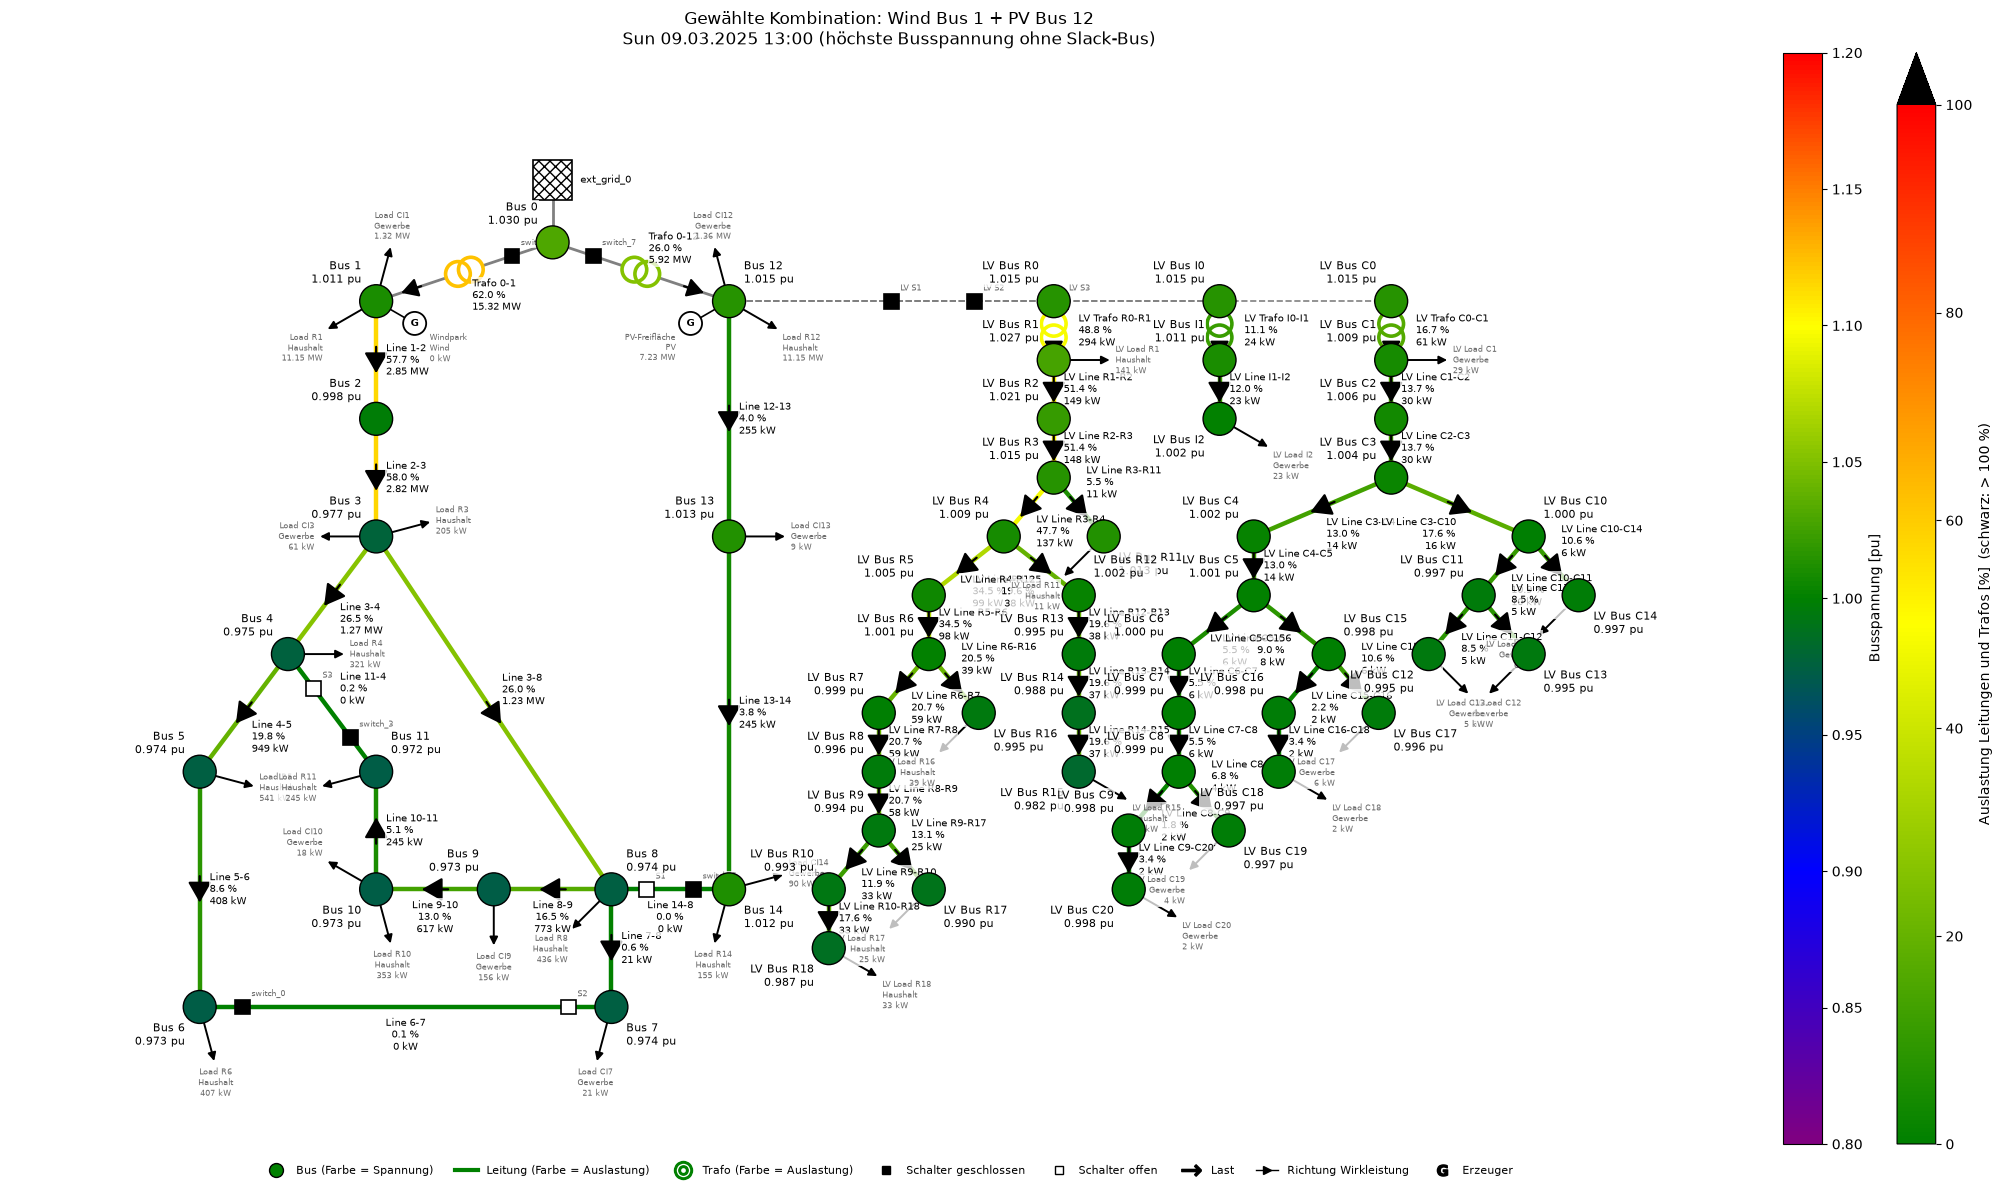

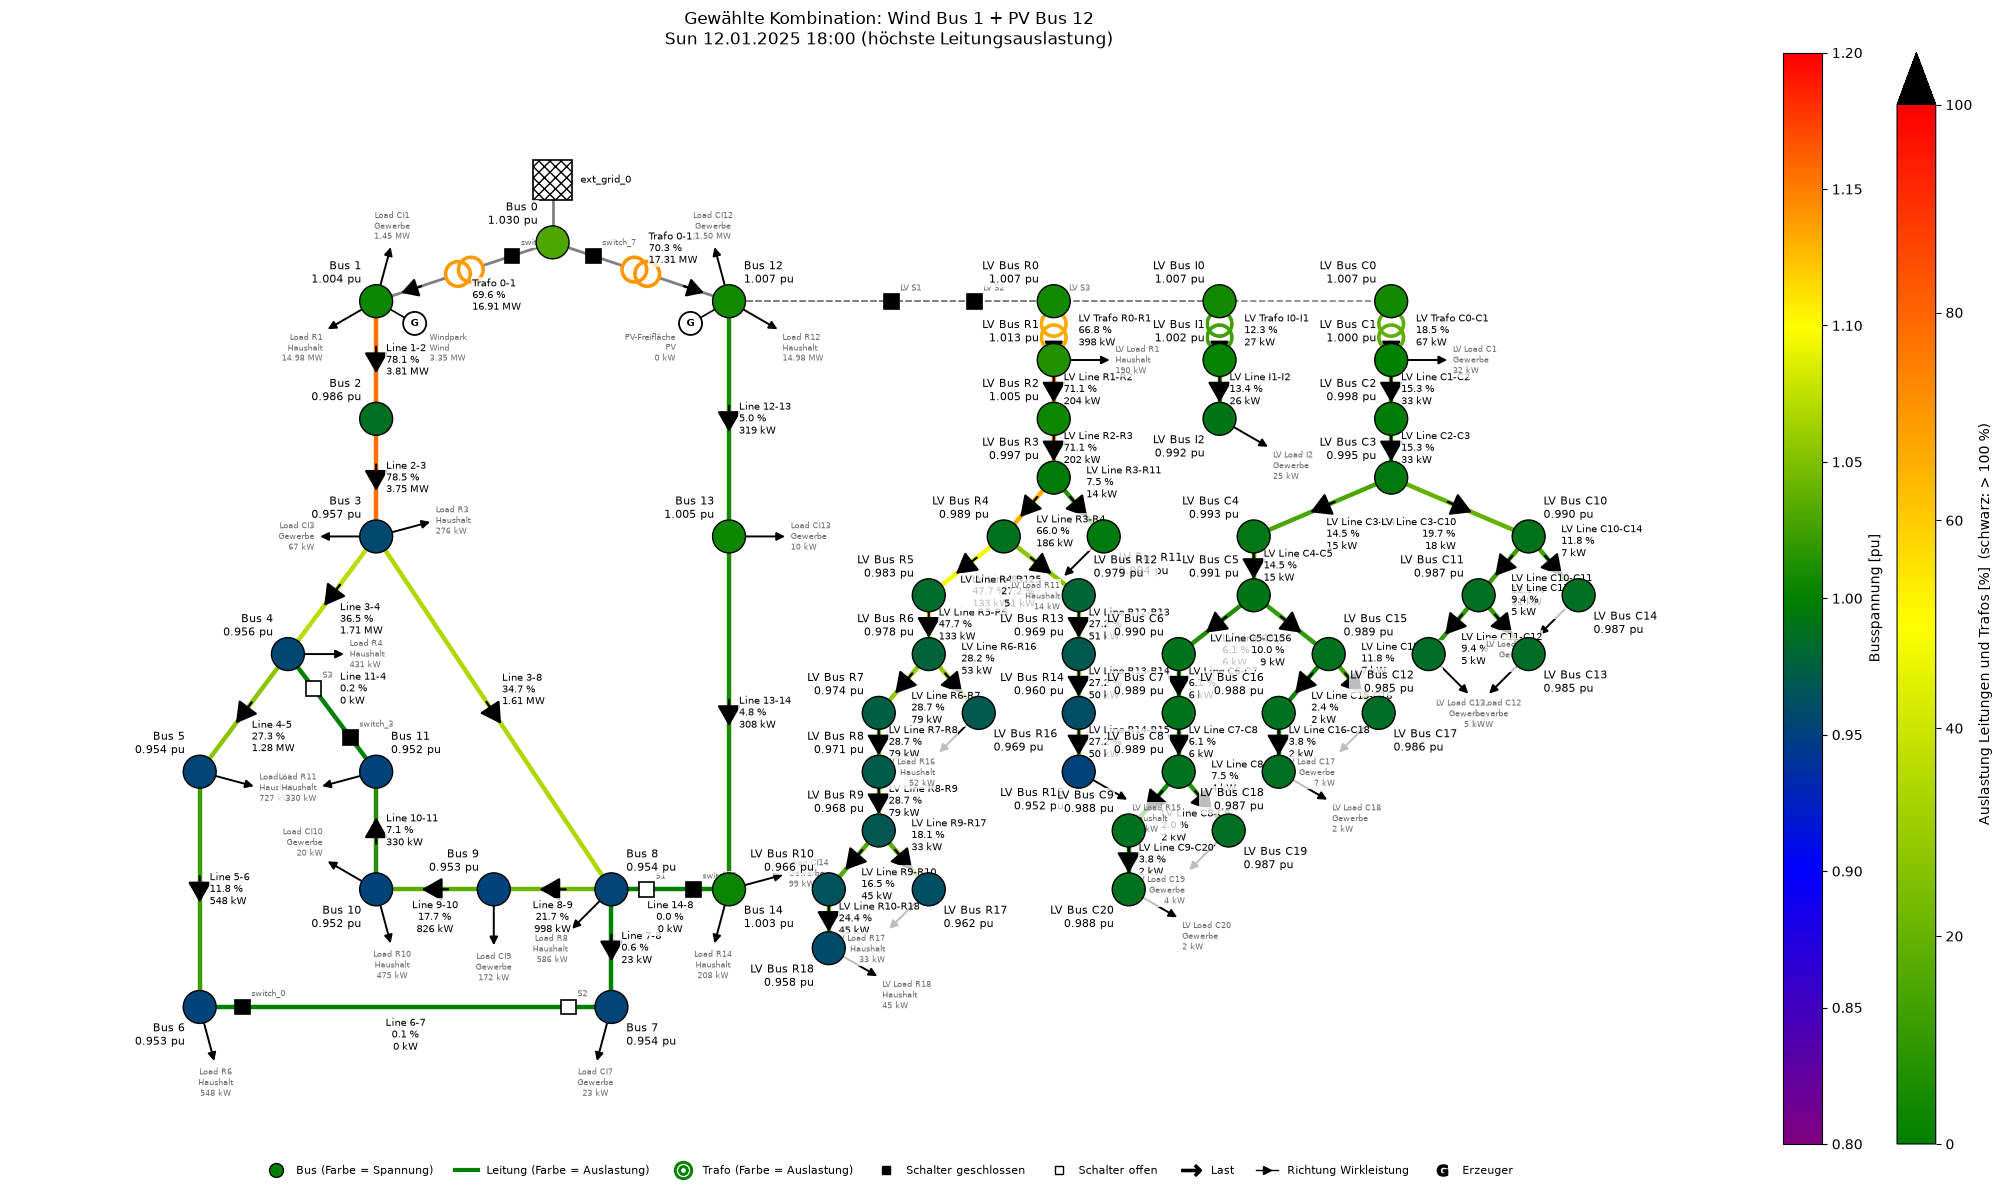

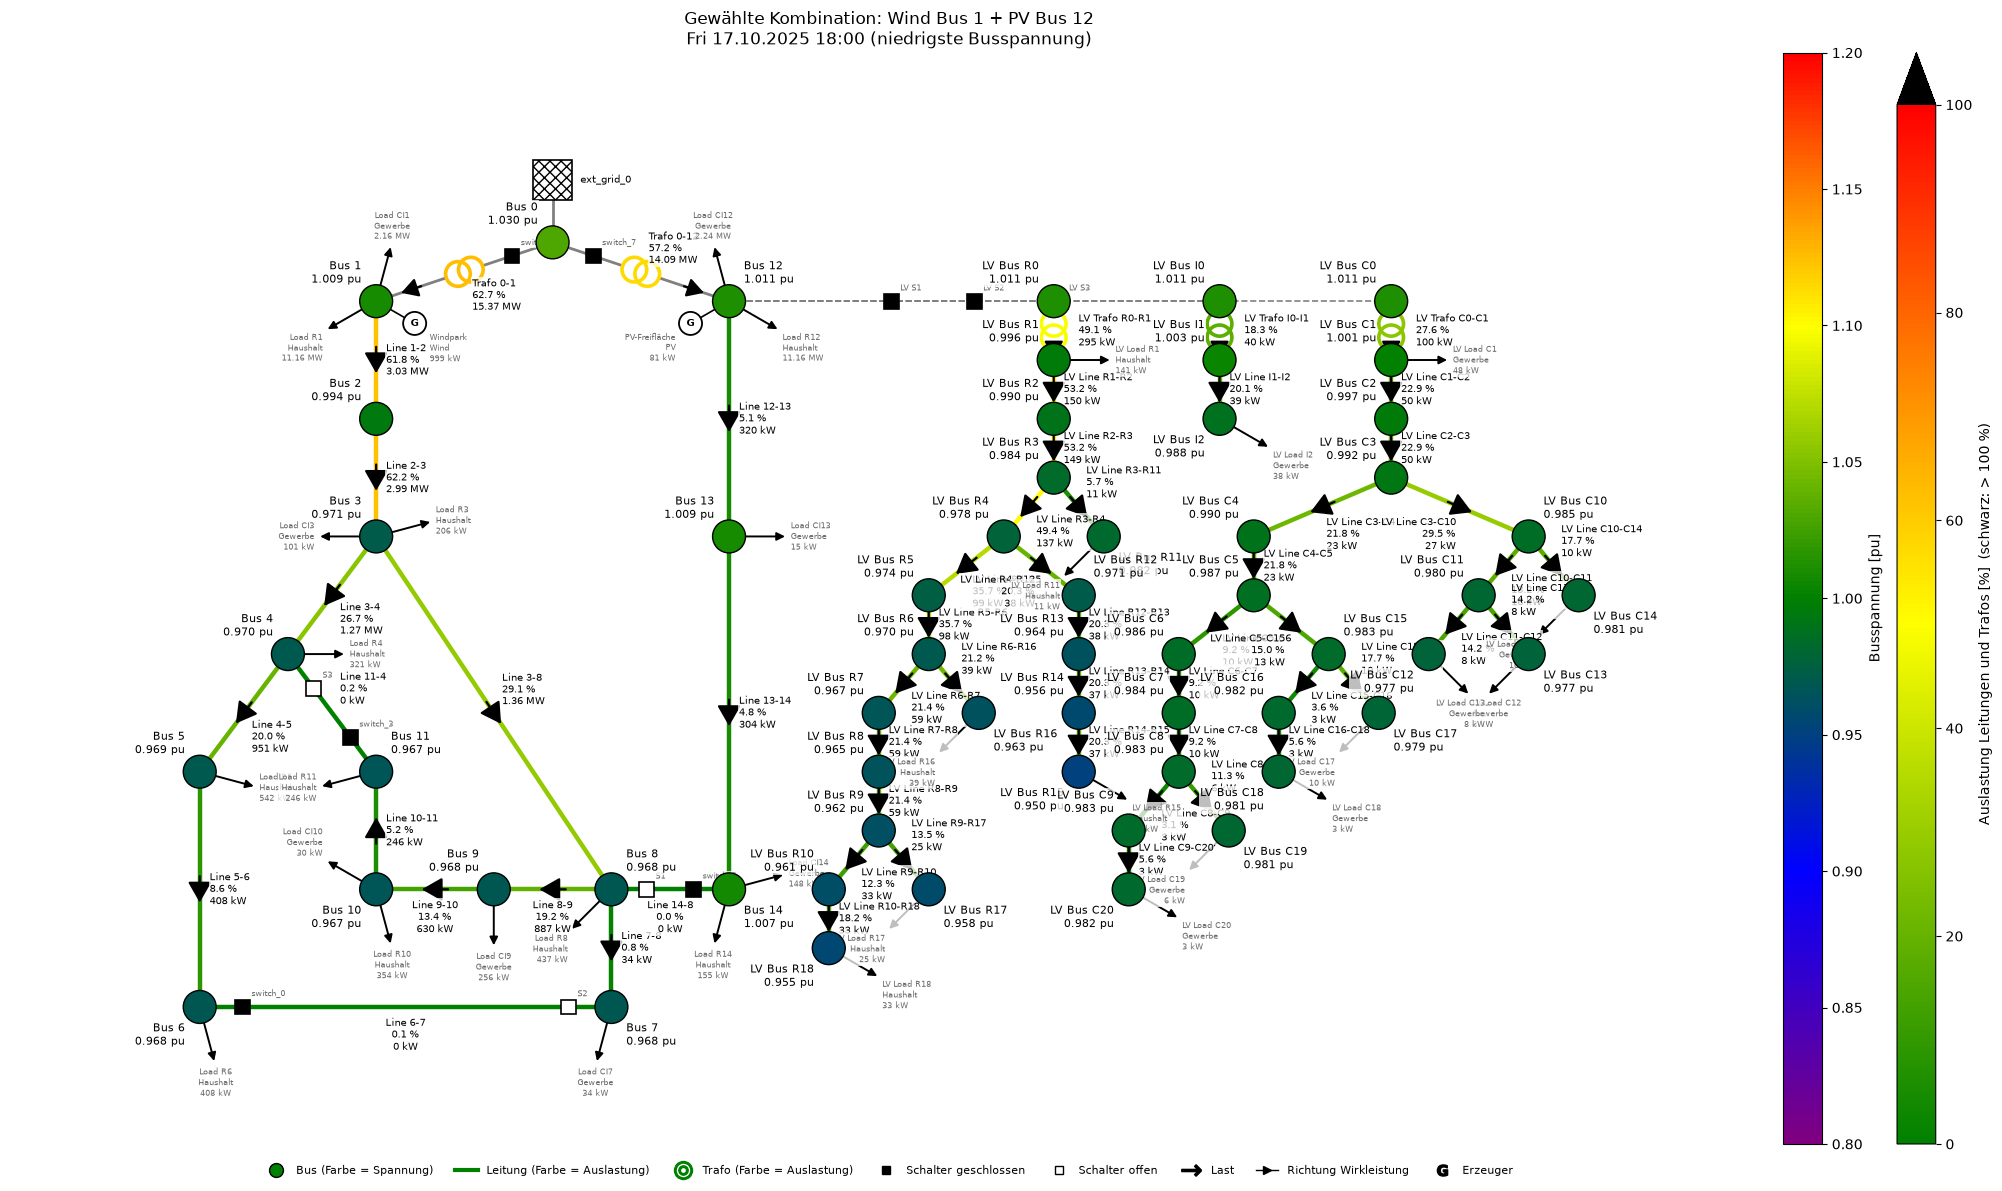

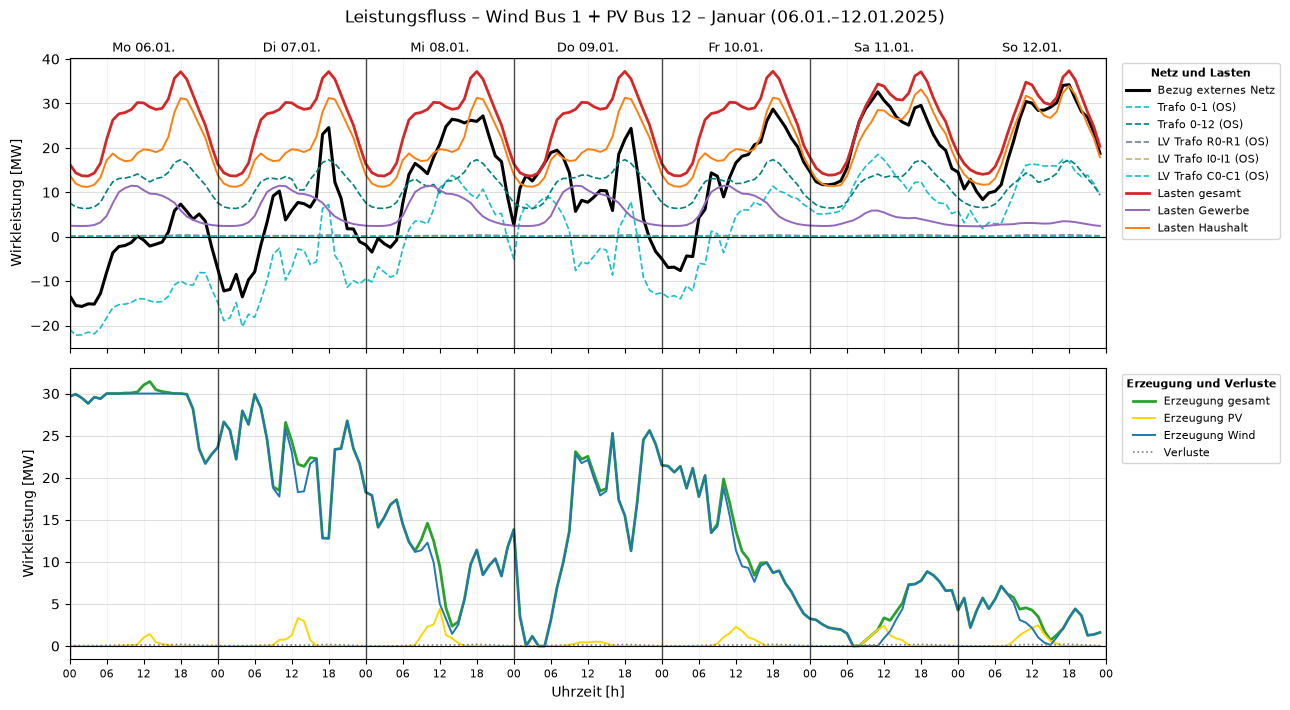

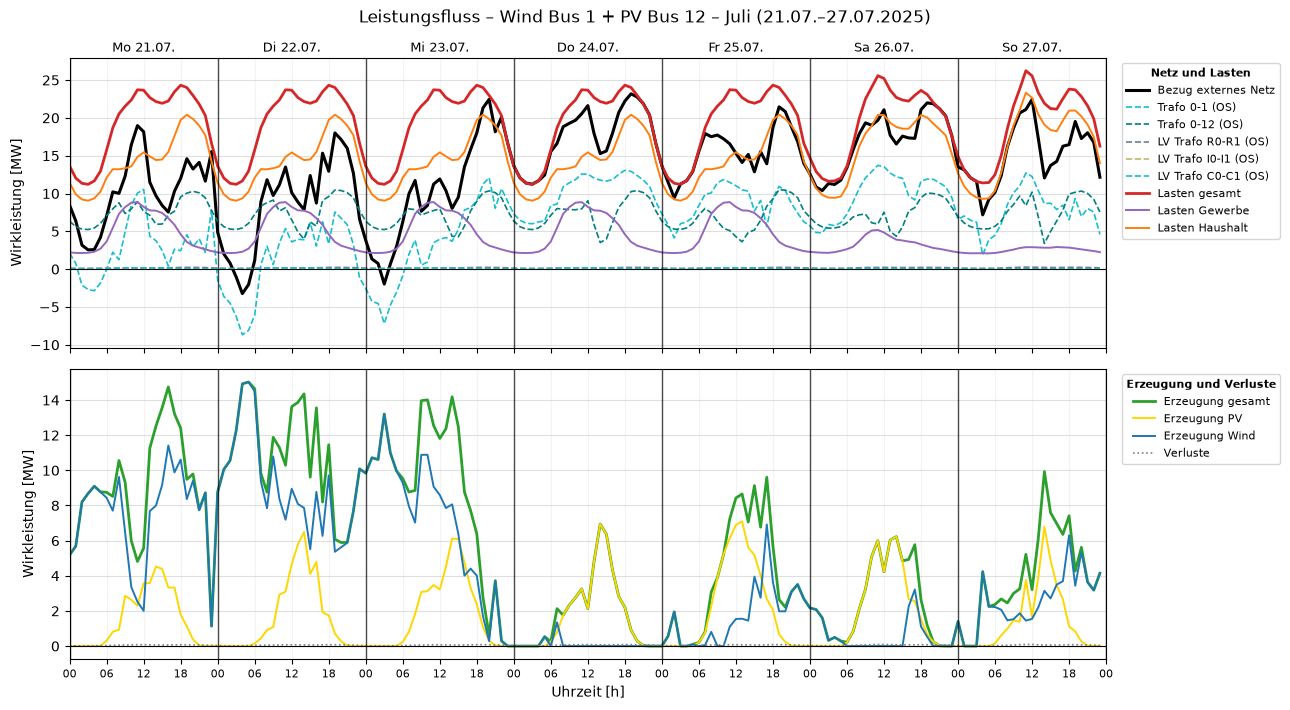

In [15]:
best = kombi[k_best]
best.createDiagram(Diagram.NETWORK, time=["max", "max_loading", "min"], title=f"Gewählte Kombination: {k_best}")
best.createDiagram(Diagram.POWER_FLOW, months=[Month.JANUARY, Month.JULY], title=f"Leistungsfluss – {k_best}")

**Entscheidung:** **Windpark an Bus 1, PV-Anlage an Bus 12** (Rangsumme 11; Wind Bus 12 + PV Bus 1: 12; die beiden Kombinationen mit beiden Anlagen am selben Bus: je 13).

Den Ausschlag geben jetzt zwei Unterschiede, die deutlich über den Relevanzschwellen liegen:

1. **(n-1): Erzeugung an einem Trafo.** Werden Windpark und PV-Anlage auf beide Trafos verteilt, gehen bei einem Trafoausfall höchstens 30 MW statt 40 MW verloren. Damit scheiden die Kombinationen mit beiden Anlagen am selben Bus aus der Spitzengruppe aus. Bisher hatten zwischen „PV an Bus 1“ und „PV an Bus 12“ nur die Verluste (0,9 %) entschieden.
2. **Normalbetrieb: Trafoauslastung.** Mit dem Windpark an Bus 1 ist der höchstbelastete 110/20-kV-Trafo um 3,8 Prozentpunkte weniger ausgelastet als mit dem Windpark an Bus 12.

Alle übrigen Unterschiede liegen unter den Relevanzschwellen und gelten als gleichwertig. Die Verluste werden nicht mehr gebraucht. Das Ergebnis ist dasselbe wie mit der bisherigen Rangfolge, aber jetzt mit einer belastbaren Begründung.

Zu beachten: Bei den Stunden unter dem Planungsband im (n-1)-Fall liegt Wind Bus 12 + PV Bus 1 mit 237 Stunden etwas besser als die gewählte Kombination mit 249 Stunden. Der Unterschied liegt mit 5 % unter der Relevanzschwelle von 10 %. Die Arbeitsgrenzen werden in beiden Fällen nie verletzt.

## 5 Ortsnetz mit PV-Haushalten (Szenario 2)

Im Ortsnetz erhält ein Teil der Haushalte die BDEW-Profile für Haushalte mit PV (P25) bzw. mit PV und Speicher (S25). Die Profile beschreiben den **Netzbezug** dieser Haushalte; die PV-Einspeisung ist nicht enthalten und wird bei den BDEW-Profilen über eigene Erzeugungsprofile abgebildet [1, S. 4–5]. Das Szenario zeigt damit, wie sich der Strombezug der Haushalte durch PV und Speicher verändert; eine Rückspeisung aus den Haushalten bildet es nicht ab.

**Aufteilung:** Jede Haushaltslast im Ortsnetz (`LV Load R…`) wird in drei Teillasten aufgeteilt (H25, P25, S25). Jede Teillast erhält den entsprechenden Anteil der ursprünglichen Höchstleistung, weil sich die Winter-Abendspitze eines Haushalts durch PV kaum ändert. Der Jahresverbrauch folgt daraus wie bisher über die Höchstleistung des jeweiligen Profils.

| Variante | Haushalte mit PV (P25) | Haushalte mit PV und Speicher (S25) | Haushalte ohne PV (H25) | Quelle |
|---|---|---|---|---|
| heute | 8,3 % | 6,7 % | 85 % | KfW: fast 15 % der Haushalte mit PV, 6,7 % mit Batteriespeicher [23] |
| Zukunft | 10 % | 40 % | 50 % | Annahme: 50 % der Haushalte mit PV; fast 80 % der neuen privaten Aufdachanlagen mit Speicher [24] |

Ein Speicher wird praktisch immer zusammen mit einer PV-Anlage betrieben; die 6,7 % mit Speicher sind deshalb eine Teilmenge der 15 % mit PV.

In [30]:
VARIANTEN = {"heute": (0.083, 0.067), "Zukunft": (0.10, 0.40)}
ortsnetz = {}
for name, (a_pv, a_sp) in VARIANTEN.items():
    s = ausgelegt.copy(f"w4_ortsnetz_pv_{name}", overwrite=True)
    aufteilung = lvnetz.prosumer(s, a_pv, a_sp)
    s.runSimulation(controllers=rg.standard_regler(s.net))
    ortsnetz[name] = s
    print(name); display(aufteilung.round(4))

Simulation 'w4_ortsnetz_pv_heute': unverändert seit dem Lauf vom 2026-11-04T15:07:03 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
heute


,Bus,p_mw vorher,H25,P25,S25
Last,,,,,
LV Load R1,LV Bus R1,0.1900,0.1615,0.0158,0.0127
LV Load R11,LV Bus R11,0.0142,0.0121,0.0012,0.0010
LV Load R15,LV Bus R15,0.0494,0.0420,0.0041,0.0033
LV Load R16,LV Bus R16,0.0522,0.0444,0.0043,0.0035
LV Load R17,LV Bus R17,0.0332,0.0283,0.0028,0.0022
LV Load R18,LV Bus R18,0.0446,0.0380,0.0037,0.0030


Simulation 'w4_ortsnetz_pv_Zukunft': unverändert seit dem Lauf vom 2026-11-04T15:08:04 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Zukunft


,Bus,p_mw vorher,H25,P25,S25
Last,,,,,
LV Load R1,LV Bus R1,0.1900,0.0950,0.0190,0.0760
LV Load R11,LV Bus R11,0.0142,0.0071,0.0014,0.0057
LV Load R15,LV Bus R15,0.0494,0.0247,0.0049,0.0198
LV Load R16,LV Bus R16,0.0522,0.0261,0.0052,0.0209
LV Load R17,LV Bus R17,0.0332,0.0166,0.0033,0.0133
LV Load R18,LV Bus R18,0.0446,0.0223,0.0045,0.0179


In [17]:
vergleich = {"Normalbetrieb": normal, **{f"PV-Haushalte {k}": s for k, s in ortsnetz.items()}}
o_werte, o_orte = bw.kennwerte(vergleich)
lv_last = {k: s.results.load_p_mw[[c for c in s.results.load_p_mw if c.startswith("LV Load R")]].sum().sum() for k, s in vergleich.items()}
o_werte["Energie Haushalte Ortsnetz [MWh]"] = pd.Series(lv_last)
o_werte["Stufenschritte R"] = [rg.schaltvorgaenge(s).get("Stufenschritte LV Trafo R0-R1", 0) for s in vergleich.values()]
plots.table(o_werte[["U min NS [pu]", "U max NS [pu]", "Stunden U < 0,95 NS", "Ortsnetztrafo max [%]",
                     "Energie Haushalte Ortsnetz [MWh]", "Stufenschritte R"]].astype(float).T, decimals=3)

,Normalbetrieb,PV-Haushalte heute,PV-Haushalte Zukunft
U min NS [pu],0.950,0.950,0.951
U max NS [pu],1.027,1.026,1.026
"Stunden U < 0,95 NS",0.000,0.000,0.000
Ortsnetztrafo max [%],66.838,65.830,63.836
Energie Haushalte Ortsnetz [MWh],389.863,365.747,292.259
Stufenschritte R,92.000,80.000,58.000


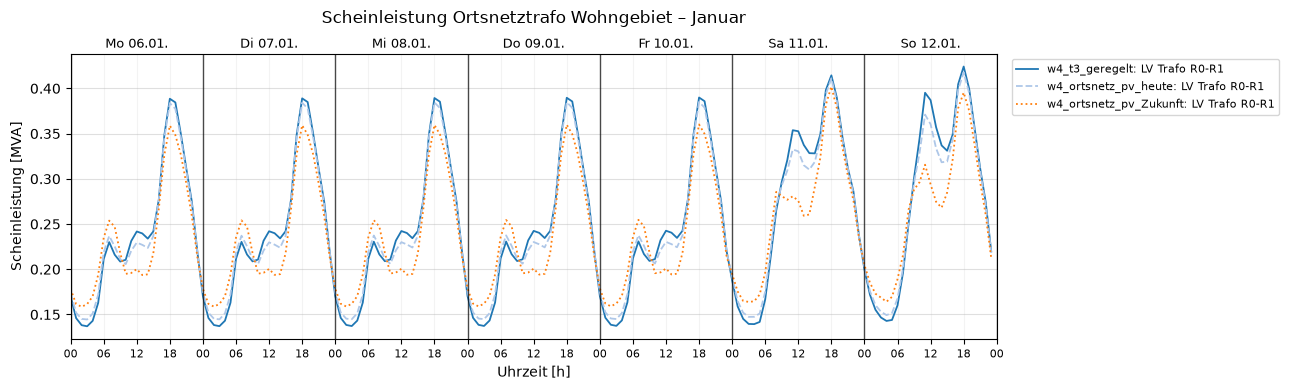

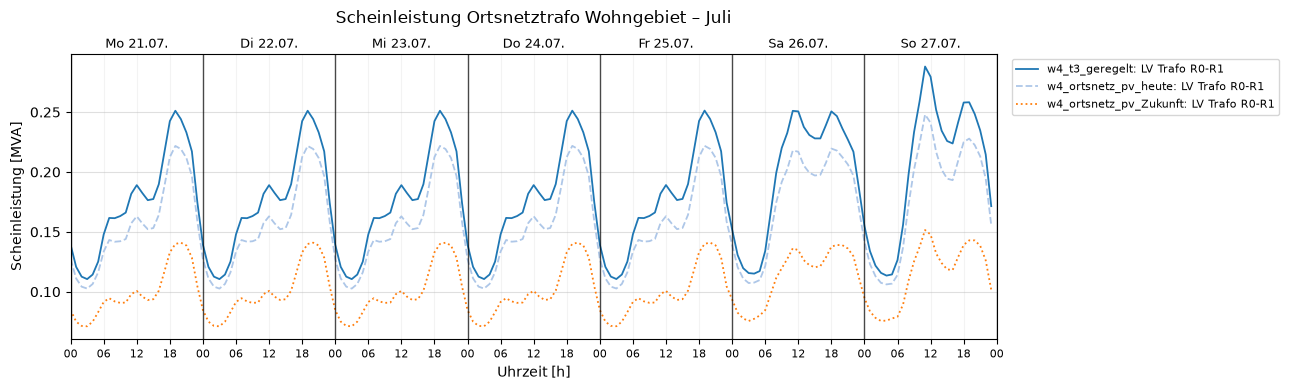

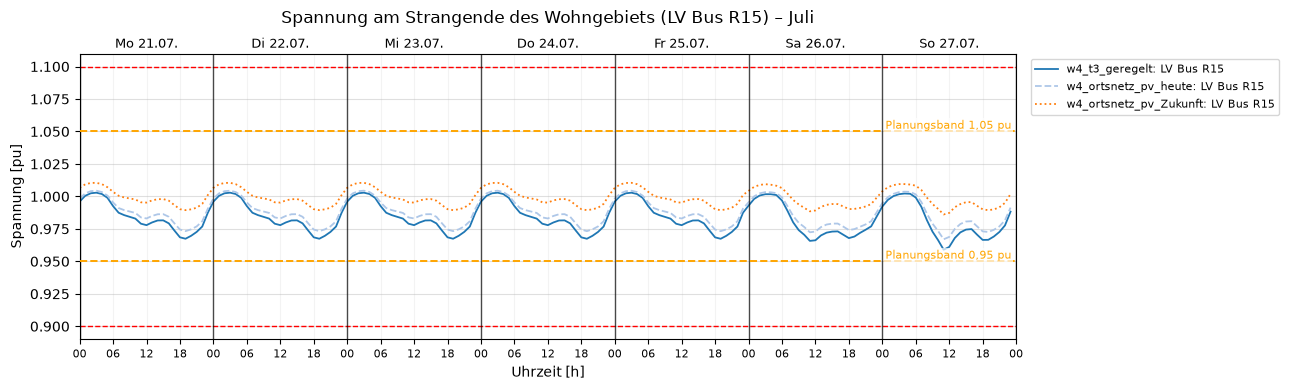

In [37]:
sim.compare(list(vergleich.values()), Diagram.APPARENT_POWER, ["LV Trafo R0-R1"], months=[Month.JANUARY, Month.JULY],
            title="Scheinleistung Ortsnetztrafo Wohngebiet")
sim.compare(list(vergleich.values()), Diagram.VOLTAGE, ["LV Bus R15"], months=[Month.JULY], markers=PLAN_MARKER,
            title="Spannung am Strangende des Wohngebiets (LV Bus R15)")

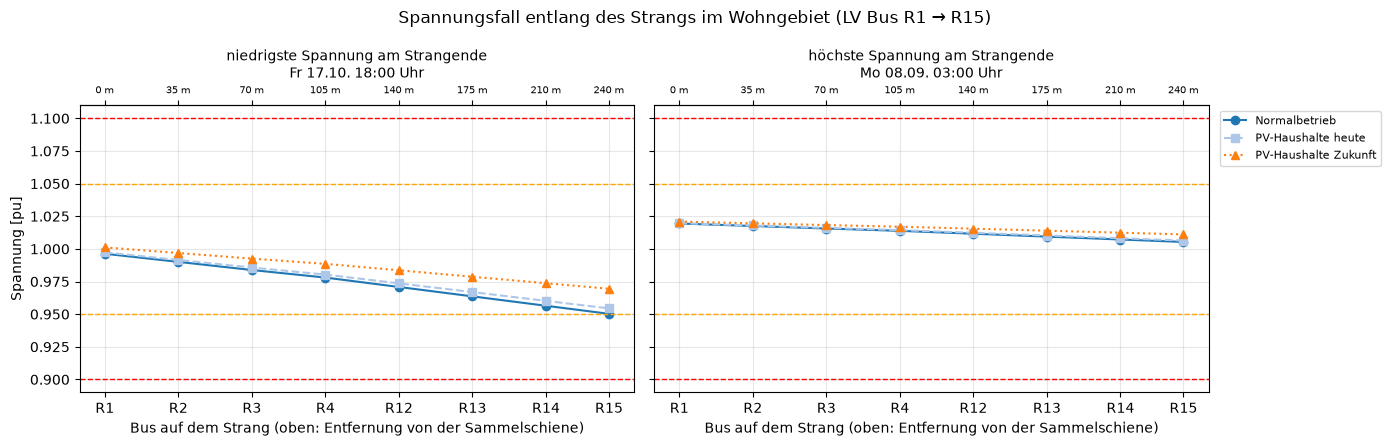

In [36]:
import networkx as nx
import pandapower.topology as top

def strangpfad(net, start, ende):
    """Busse auf dem Weg von start nach ende und die Entfernung vom Start in km."""
    graph = top.create_nxgraph(net, include_trafos=False)
    idx = dict(zip(net.bus["name"], net.bus.index))
    pfad = nx.shortest_path(graph, idx[start], idx[ende])
    km = [0.0]
    for a, b in zip(pfad[:-1], pfad[1:]):
        km.append(km[-1] + min(d["weight"] for d in graph.get_edge_data(a, b).values()))
    return [net.bus.at[b, "name"] for b in pfad], km

TAGE = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]
busse, km = strangpfad(vergleich["Normalbetrieb"].net, "LV Bus R1", "LV Bus R15")
ref = vergleich["Normalbetrieb"].results.vm_pu[busse[-1]]
zeitpunkte = {"niedrigste Spannung am Strangende": ref.idxmin(),
              "höchste Spannung am Strangende": ref.idxmax()}

V_MIN = 0.9
V_PLAN_MIN = 0.95
V_MAX = 1.1
V_PLAN_MAX = 1.05

fig, axes = plt.subplots(1, len(zeitpunkte), figsize=(14, 4.5), sharey=True)
for ax, (titel, t) in zip(axes, zeitpunkte.items()):
    for (name, s), stil in zip(vergleich.items(), ("o-", "s--", "^:")):
        ax.plot(km, s.results.vm_pu.loc[t, busse], stil, label=name)
    for v, farbe in ((V_MIN, "red"), (V_PLAN_MIN, "orange"), (V_PLAN_MAX, "orange"), (V_MAX, "red")):
        ax.axhline(v, color=farbe, ls="--", lw=1)
    ax.set_xticks(km, [b.replace("LV Bus ", "") for b in busse])
    oben = ax.secondary_xaxis("top")
    oben.set_xticks(km, [f"{x * 1000:.0f} m" for x in km], fontsize=7)
    ax.set_title(f"{titel}\n{TAGE[t.weekday()]} {t:%d.%m. %H:%M} Uhr", fontsize=10)
    ax.set_xlabel("Bus auf dem Strang (oben: Entfernung von der Sammelschiene)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Spannung [pu]")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.suptitle("Spannungsfall entlang des Strangs im Wohngebiet (LV Bus R1 → R15)")
plt.tight_layout()
plt.show()

**Ergebnis Ortsnetz mit PV-Haushalten:**

| Kennwert | Normalbetrieb | PV-Haushalte heute | PV-Haushalte Zukunft |
|---|---|---|---|
| Energie Haushalte im Ortsnetz (12 Wochen) | 390 MWh | 366 MWh (−6 %) | 292 MWh (−25 %) |
| Ortsnetztrafo Wohngebiet, höchste Auslastung im Juli | 45,1 % | 38,8 % | 23,7 % |
| Ortsnetztrafo Wohngebiet, höchste Auslastung im Januar | 66,8 % | 65,8 % | 63,3 % |
| Stufenschritte rONT Wohngebiet | 92 | 80 | 58 |
| niedrigste / höchste NS-Spannung | 0,950 / 1,027 pu | 0,950 / 1,026 pu | 0,951 / 1,026 pu |

- PV und Speicher senken den **Strombezug** der Haushalte, vor allem im Sommer: Im Zukunftsszenario ist der Ortsnetztrafo im Juli nur noch halb so stark ausgelastet. Die **Winterspitze** bleibt fast gleich, weil PV am Winterabend nicht einspeist und die Speicher im Winter kaum geladen werden. Für die Auslegung der Betriebsmittel ändert sich deshalb wenig.
- Der rONT muss seltener eingreifen (58 statt 92 Stufenschritte im Wohngebiet), weil die Spannung am Strangende im Sommer weniger absinkt. Im Gewerbenetz ändert sich nichts.
- Weil die BDEW-Profile P25 und S25 nur den Netzbezug enthalten, entsteht in diesem Szenario keine Rückspeisung aus den Haushalten und keine Spannungsanhebung im Ortsnetz. Das ist eine Grenze des gewählten Modells.

## 6 (n-1)-Auswertung der gewählten Kombination

Ausführliche Prüfung der in 4.3 gewählten Kombination: Gilt der Wiederversorgungsplan aus Teil 3b auch mit Windpark und PV-Anlage, was passiert beim Ausfall eines 110/20-kV-Trafos, und wie verhält sich das Netz über 12 Wochen, wenn eine Leitung ausgefallen ist?

### 6.1 Betriebspunkte

In [19]:
WIEDERVERSORGUNG_3B = {"Line 1-2": ["S1"], "Line 2-3": ["S1"], "Line 3-4": ["S2"], "Line 4-5": ["S2"], "Line 5-6": ["S2"],
                       "Line 7-8": ["S2"], "Line 8-9": ["S3"], "Line 9-10": ["S3"], "Line 10-11": ["S3"], "Line 3-8": ["S2"],
                       "Line 12-13": ["S1"], "Line 13-14": ["S1"]}      # Ergebnis von Teil 3b, Abschnitt 6.3

print("Gewählte Kombination:", k_best)
r = best.results
punkte = rg.kritische_stunden(best)
pd.DataFrame({bp: {"Zeitpunkt": f"{h:%d.%m. %H:%M}", "Windpark [MW]": r.sgen_p_mw.at[h, "Windpark"],
                   "PV-Anlage [MW]": r.sgen_p_mw.at[h, "PV-Freifläche"], "Last [MW]": r.load_p_mw.loc[h].sum(),
                   "Austausch 110 kV [MW] (− = Rückspeisung)": r.ext_grid_p_mw.squeeze()[h]}
              for bp, h in punkte.items()}).T

Gewählte Kombination: Wind Bus 1 + PV Bus 12


,Zeitpunkt,Windpark [MW],PV-Anlage [MW],Last [MW],Austausch 110 kV [MW] (− = Rückspeisung)
Jahreshöchstlast,05.02. 18:00,0.921,0.0,36.588826,35.872586
max. Rückspeisung,19.12. 02:00,29.487,0.0,13.331587,-16.099811
max. Erzeugung,08.02. 12:00,29.931,6.024,32.662988,-3.149533


### 6.2 Leitungsausfälle

Übersicht je Betriebspunkt (✔ = zulässig; sonst Zahl der nicht versorgten Busse bzw. Grund):

In [20]:
def status(row):
    if row["Bemerkung"]:
        return "✘ " + row["Bemerkung"]
    k = int(row["nicht versorgte Busse"])
    if k > 0:
        return f"{k} Bus unversorgt" if k == 1 else f"{k} Busse unversorgt"
    return "✔" if row["zulässig"] else "✘ Grenze verletzt"

leitungen = [a for a in AUSFAELLE if a.startswith("Line")]
for bp in punkte:
    an = n1_statisch[(k_best, bp)]
    print(bp)
    display(an.assign(Status=an.apply(status, axis=1)).pivot(index="Ausfall", columns="Maßnahme", values="Status")
              .loc[leitungen, list(dict.fromkeys(an["Maßnahme"]))])

Jahreshöchstlast


Maßnahme,keine,S2 schließen,S3 schließen,S1 schließen,S2 schließen + S3 schließen,S2 schließen + S1 schließen,S3 schließen + S1 schließen,S2 schließen + S3 schließen + S1 schließen
Ausfall,,,,,,,,
Line 1-2,10 Busse unversorgt,10 Busse unversorgt,10 Busse unversorgt,✔,10 Busse unversorgt,✔,✔,✔
Line 2-3,9 Busse unversorgt,9 Busse unversorgt,9 Busse unversorgt,✔,9 Busse unversorgt,✔,✔,✔
Line 3-4,3 Busse unversorgt,✔,✔,3 Busse unversorgt,✔,✔,✔,✔
Line 4-5,2 Busse unversorgt,✔,2 Busse unversorgt,2 Busse unversorgt,✔,✔,2 Busse unversorgt,✔
Line 5-6,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 7-8,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 8-9,3 Busse unversorgt,3 Busse unversorgt,✔,3 Busse unversorgt,✔,3 Busse unversorgt,✔,✔
Line 9-10,2 Busse unversorgt,2 Busse unversorgt,✔,2 Busse unversorgt,✔,2 Busse unversorgt,✔,✔
Line 10-11,1 Bus unversorgt,1 Bus unversorgt,✔,1 Bus unversorgt,✔,1 Bus unversorgt,✔,✔


max. Rückspeisung


Maßnahme,keine,S2 schließen,S3 schließen,S1 schließen,S2 schließen + S3 schließen,S2 schließen + S1 schließen,S3 schließen + S1 schließen,S2 schließen + S3 schließen + S1 schließen
Ausfall,,,,,,,,
Line 1-2,10 Busse unversorgt,10 Busse unversorgt,10 Busse unversorgt,✔,10 Busse unversorgt,✔,✔,✔
Line 2-3,9 Busse unversorgt,9 Busse unversorgt,9 Busse unversorgt,✔,9 Busse unversorgt,✔,✔,✔
Line 3-4,3 Busse unversorgt,✔,✔,3 Busse unversorgt,✔,✔,✔,✔
Line 4-5,2 Busse unversorgt,✔,2 Busse unversorgt,2 Busse unversorgt,✔,✔,2 Busse unversorgt,✔
Line 5-6,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 7-8,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 8-9,3 Busse unversorgt,3 Busse unversorgt,✔,3 Busse unversorgt,✔,3 Busse unversorgt,✔,✔
Line 9-10,2 Busse unversorgt,2 Busse unversorgt,✔,2 Busse unversorgt,✔,2 Busse unversorgt,✔,✔
Line 10-11,1 Bus unversorgt,1 Bus unversorgt,✔,1 Bus unversorgt,✔,1 Bus unversorgt,✔,✔


max. Erzeugung


Maßnahme,keine,S2 schließen,S3 schließen,S1 schließen,S2 schließen + S3 schließen,S2 schließen + S1 schließen,S3 schließen + S1 schließen,S2 schließen + S3 schließen + S1 schließen
Ausfall,,,,,,,,
Line 1-2,10 Busse unversorgt,10 Busse unversorgt,10 Busse unversorgt,✔,10 Busse unversorgt,✔,✔,✔
Line 2-3,9 Busse unversorgt,9 Busse unversorgt,9 Busse unversorgt,✔,9 Busse unversorgt,✔,✔,✔
Line 3-4,3 Busse unversorgt,✔,✔,3 Busse unversorgt,✔,✔,✔,✔
Line 4-5,2 Busse unversorgt,✔,2 Busse unversorgt,2 Busse unversorgt,✔,✔,2 Busse unversorgt,✔
Line 5-6,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 7-8,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 8-9,3 Busse unversorgt,3 Busse unversorgt,✔,3 Busse unversorgt,✔,3 Busse unversorgt,✔,✔
Line 9-10,2 Busse unversorgt,2 Busse unversorgt,✔,2 Busse unversorgt,✔,2 Busse unversorgt,✔,✔
Line 10-11,1 Bus unversorgt,1 Bus unversorgt,✔,1 Bus unversorgt,✔,1 Bus unversorgt,✔,✔


Wiederversorgungsplan je Betriebspunkt im Vergleich mit dem Plan aus Teil 3b (ohne Erzeuger):

In [21]:
plaene = {bp: rg.wiederversorgungsplan(n1_statisch[(k_best, bp)]) for bp in punkte}
vergleich_plan = pd.DataFrame({bp: p.loc[leitungen, "Maßnahme"] for bp, p in plaene.items()})
vergleich_plan["Teil 3b"] = [" + ".join(f"{x} schließen" for x in WIEDERVERSORGUNG_3B[a]) for a in leitungen]
vergleich_plan["gleich"] = vergleich_plan.nunique(axis=1).eq(1).map({True: "✔", False: "✘"})
display(vergleich_plan)

zustand = pd.concat({bp: p.loc[leitungen, ["U min MS [pu]", "U max MS [pu]", "Leitung max MS [%]", "am stärksten belastet",
                                           "Trafo max HS/MS [%]"]] for bp, p in plaene.items()}, axis=1)
plots.table(zustand, decimals=3)

,Jahreshöchstlast,max. Rückspeisung,max. Erzeugung,Teil 3b,gleich
Ausfall,,,,,
Line 1-2,S1 schließen,S1 schließen,S1 schließen,S1 schließen,✔
Line 2-3,S1 schließen,S1 schließen,S1 schließen,S1 schließen,✔
Line 3-4,S2 schließen,S2 schließen,S2 schließen,S2 schließen,✔
Line 4-5,S2 schließen,S2 schließen,S2 schließen,S2 schließen,✔
Line 5-6,S2 schließen,S2 schließen,S2 schließen,S2 schließen,✔
Line 7-8,S2 schließen,S2 schließen,S2 schließen,S2 schließen,✔
Line 8-9,S3 schließen,S3 schließen,S3 schließen,S3 schließen,✔
Line 9-10,S3 schließen,S3 schließen,S3 schließen,S3 schließen,✔
Line 10-11,S3 schließen,S3 schließen,S3 schließen,S3 schließen,✔


**Ergebnis Leitungsausfälle:**

- Der Wiederversorgungsplan aus Teil 3b gilt **unverändert** auch mit Windpark und PV-Anlage: In allen drei Betriebspunkten wird für jede Leitung dieselbe Trennstelle gewählt (S2 für Line 3-4 bis 7-8 und 3-8, S3 für Line 8-9 bis 10-11, S1 für Line 1-2, 2-3, 12-13 und 13-14).
- **Jahreshöchstlast:** Der Windpark speist fast nichts ein (0,9 MW). Der Zustand entspricht deshalb dem Netz ohne Erzeuger: niedrigste MS-Spannung 0,928 pu (Ausfall Line 2-3), höchste Trafoauslastung 85,7 %.
- **Max. Rückspeisung** (29,5 MW Wind, 13,3 MW Last): Die Spannungen liegen hoch (bis 1,023 pu), aber im Band. Die höchste Trafoauslastung tritt beim Ausfall von Line 1-2 oder 2-3 auf (93,0 %): Trafo 0-1 versorgt dann nur noch Bus 1 (und Bus 2), und fast die ganze Windleistung fließt über ihn ins 110-kV-Netz zurück.
- **Max. Erzeugung** (29,9 MW Wind + 6,0 MW PV, 32,7 MW Last): Dieser Betriebspunkt ist unkritisch, weil Erzeugung und Last sich fast ausgleichen.

### 6.3 Ausfall eines 110/20-kV-Transformators

In [22]:
trafo_faelle = pd.concat([n1_statisch[(k_best, bp)].assign(Betriebspunkt=bp) for bp in punkte])
trafo_faelle = trafo_faelle[trafo_faelle.Ausfall.str.startswith("Trafo") & trafo_faelle["Maßnahme"].isin(["keine", "S1 schließen"])]
plots.table(trafo_faelle.set_index(["Betriebspunkt", "Ausfall", "Maßnahme"])[
    ["nicht versorgte Busse", "getrennte Erzeugung [MW]", "U min MS [pu]", "U max MS [pu]", "Leitung max MS [%]",
     "am stärksten belastet", "Trafo max HS/MS [%]", "Bemerkung"]], decimals=2)

**Vergleich mit einer Längskupplung im Umspannwerk (hypothetisch):** Wie in Teil 3b, Abschnitt 6.4, wird geprüft, in wie vielen Stunden ein einzelner Trafo (25 MVA) den Leistungsaustausch mit dem 110-kV-Netz allein tragen könnte, wenn die beiden 20-kV-Sammelschienen direkt gekuppelt wären. Mit Erzeugern ändert sich der Austausch: Tagsüber und bei Wind sinkt der Bezug, bei starkem Wind fließt Leistung zurück.

In [23]:
def stunden_ein_trafo(s, sn=25.0):
    rr = s.results
    S = np.hypot(rr.ext_grid_p_mw.squeeze(), rr.ext_grid_q_mvar.squeeze())
    return {"max. Scheinleistung 110 kV [MVA]": S.max(), "Stunden ≤ 25 MVA": int((S <= sn).sum()),
            "Anteil": f"{(S <= sn).mean():.0%}", "Stunden > 25 MVA bei Bezug": int(((S > sn) & (rr.ext_grid_p_mw.squeeze() > 0)).sum()),
            "Stunden > 25 MVA bei Rückspeisung": int(((S > sn) & (rr.ext_grid_p_mw.squeeze() < 0)).sum())}

pd.DataFrame({"ohne Erzeuger (Teil 3b)": stunden_ein_trafo(normal), k_best: stunden_ein_trafo(best)}).T

,max. Scheinleistung 110 kV [MVA],Stunden ≤ 25 MVA,Anteil,Stunden > 25 MVA bei Bezug,Stunden > 25 MVA bei Rückspeisung
ohne Erzeuger (Teil 3b),39.405322,1181,59%,835,0
Wind Bus 1 + PV Bus 12,37.758213,1818,90%,198,0


**Ergebnis Trafoausfall:**

- **Ohne Maßnahme** ist der Abgang des ausgefallenen Trafos ohne Versorgung, und die Erzeugung an seiner Sammelschiene wird vom Netz getrennt: beim Ausfall von Trafo 0-1 der Windpark (bis 29,9 MW), beim Ausfall von Trafo 0-12 die PV-Anlage (bis 6,0 MW in den untersuchten Stunden, installiert 10 MWp).
- **Mit S1** ist eine Wiederversorgung in keinem Betriebspunkt zulässig. Bei Jahreshöchstlast konvergiert der Lastfluss nicht (wie in Teil 3b). Bei Rückspeisung ist es noch ungünstiger: Fällt Trafo 0-1 aus und S1 wird geschlossen, muss die Windleistung von Bus 1 durch den ganzen Abgang 1, über S1 und Abgang 2 zu Trafo 0-12 fließen. Die Leitungen wären dann mit bis zu 378 % ausgelastet, und die Spannung stiege auf 1,25 pu. S1 darf in diesem Fall nicht geschlossen werden, solange der Windpark einspeist.
- **Längskupplung im Umspannwerk (hypothetisch):** Mit den Erzeugern könnte ein einzelner Trafo den Austausch mit dem 110-kV-Netz in 90 % der Stunden allein tragen (ohne Erzeuger nur in 59 %), weil Wind und PV einen Teil der Last vor Ort decken. Die höchste Rückspeisung (16,1 MW) liegt unter der Bemessungsleistung eines Trafos. Kritisch bleiben 198 Stunden mit hohem Bezug bei wenig Erzeugung (Winterabende).
- **Folgerung:** Der Ausfall eines 110/20-kV-Trafos ist weiterhin nicht (n-1)-sicher. Der Backup-Plan muss für diesen Fall ergänzt werden: Bei einem Trafoausfall wird der Windpark bzw. die PV-Anlage an der betroffenen Sammelschiene abgeschaltet, **bevor** S1 geschlossen werden darf. Eine dauerhafte Lösung wäre eine Längskupplung im Umspannwerk; die Erzeuger verbessern dann sogar die Reserve.

### 6.4 Zeitreihen mit ausgefallener Leitung

Für die Leitungen, deren Ausfall die meisten Busse betrifft oder einen Abgang über S1 umschaltet, wird die gewählte Kombination über 12 Wochen gerechnet: Die Leitung ist die ganze Zeit außer Betrieb, die Wiederversorgung schließt die Trennstelle nach dem Plan, rONT-Regler und Spannungsstützung arbeiten wie gewohnt.

In [24]:
N1_DETAIL = ["Line 1-2", "Line 2-3", "Line 3-4", "Line 3-8", "Line 8-9", "Line 12-13", "Line 13-14"]
kurz = best.name.replace("w4_kombi_", "")
detail = {"ohne Ausfall": best}
for leitung in N1_DETAIL:
    if (k_best, leitung) in n1_zeitreihe:
        detail[leitung] = n1_zeitreihe[(k_best, leitung)]
        continue
    z = best.copy(f"w4_n1_{kurz}_L{leitung.split()[1].replace('-', '_')}", overwrite=True)
    z.changeParameter(leitung, "in_service", False)
    z.runSimulation(controllers=rg.standard_regler(z.net, wiederversorgung={leitung: WIEDERVERSORGUNG_3B[leitung]}), verbose=False)
    detail[leitung] = z
d_werte, d_orte = bw.kennwerte(detail)
d_werte["Stunden außerhalb der Arbeitsgrenzen"] = d_werte[GRENZEN].sum(axis=1)
for sw in ("S1", "S2", "S3"):
    d_werte[f"Schaltungen {sw}"] = [rg.schaltvorgaenge(s).get(f"Schaltungen {sw}", 0) for s in detail.values()]
d_werte["Stufenschritte rONT gesamt"] = [int(rg.schaltvorgaenge(s).filter(like="Stufen").sum()) for s in detail.values()]
plots.table(d_werte[zcols + ["Stunden Rückspeisung 110 kV", "max. Rückspeisung 110 kV [MW]", "Schaltungen S1", "Schaltungen S2",
                     "Schaltungen S3", "Stufenschritte rONT gesamt"]].astype(float).T, decimals=3)

Hinweis: 9 Busse sind nicht versorgt (z. B. ['Bus 3', 'Bus 4', 'Bus 5', 'Bus 6', 'Bus 7']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 3 Busse sind nicht versorgt (z. B. ['Bus 4', 'Bus 5', 'Bus 6']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 5 Busse sind nicht versorgt (z. B. ['Bus 7', 'Bus 8', 'Bus 9', 'Bus 10', 'Bus 11']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 3 Busse sind nicht versorgt (z. B. ['Bus 9', 'Bus 10', 'Bus 11']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 1 Bus ist nicht versorgt (z. B. ['Bus 14']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.


,ohne Ausfall,Line 1-2,Line 2-3,Line 3-4,Line 3-8,Line 8-9,Line 12-13,Line 13-14
Stunden außerhalb der Arbeitsgrenzen,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
"Stunden U < 0,95 MS",0.000,202.000,238.000,77.000,105.000,0.000,47.000,40.000
U min MS [pu],0.951,0.933,0.932,0.940,0.936,0.951,0.942,0.942
U max MS [pu],1.025,1.025,1.026,1.025,1.025,1.025,1.025,1.025
Leitung max MS [%],78.491,65.083,65.468,79.147,78.782,78.509,86.929,86.492
Trafo max HS/MS [%],88.512,93.759,93.722,88.513,88.520,88.517,87.928,87.960
Verluste [MWh],151.602,225.771,228.721,166.621,172.199,151.390,181.535,179.602
Stunden Rückspeisung 110 kV,263.000,262.000,262.000,263.000,263.000,263.000,263.000,263.000
max. Rückspeisung 110 kV [MW],16.100,16.085,16.084,16.097,16.097,16.100,16.096,16.096
Schaltungen S1,0.000,1.000,1.000,0.000,0.000,0.000,1.000,1.000


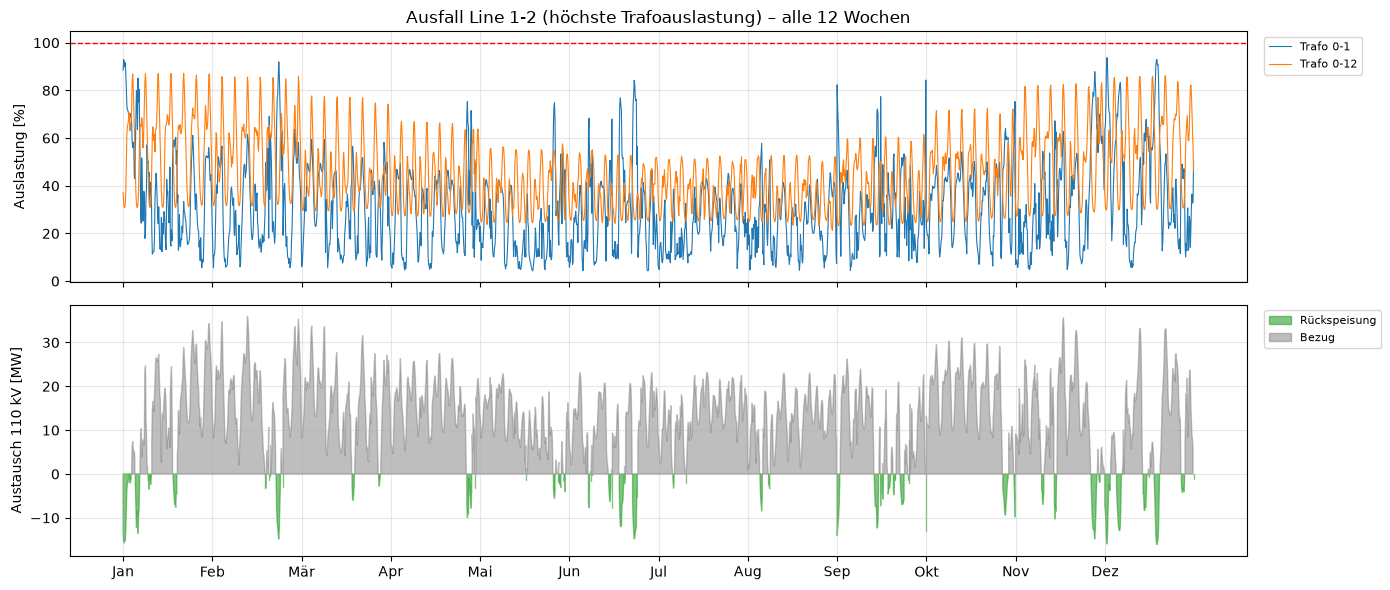

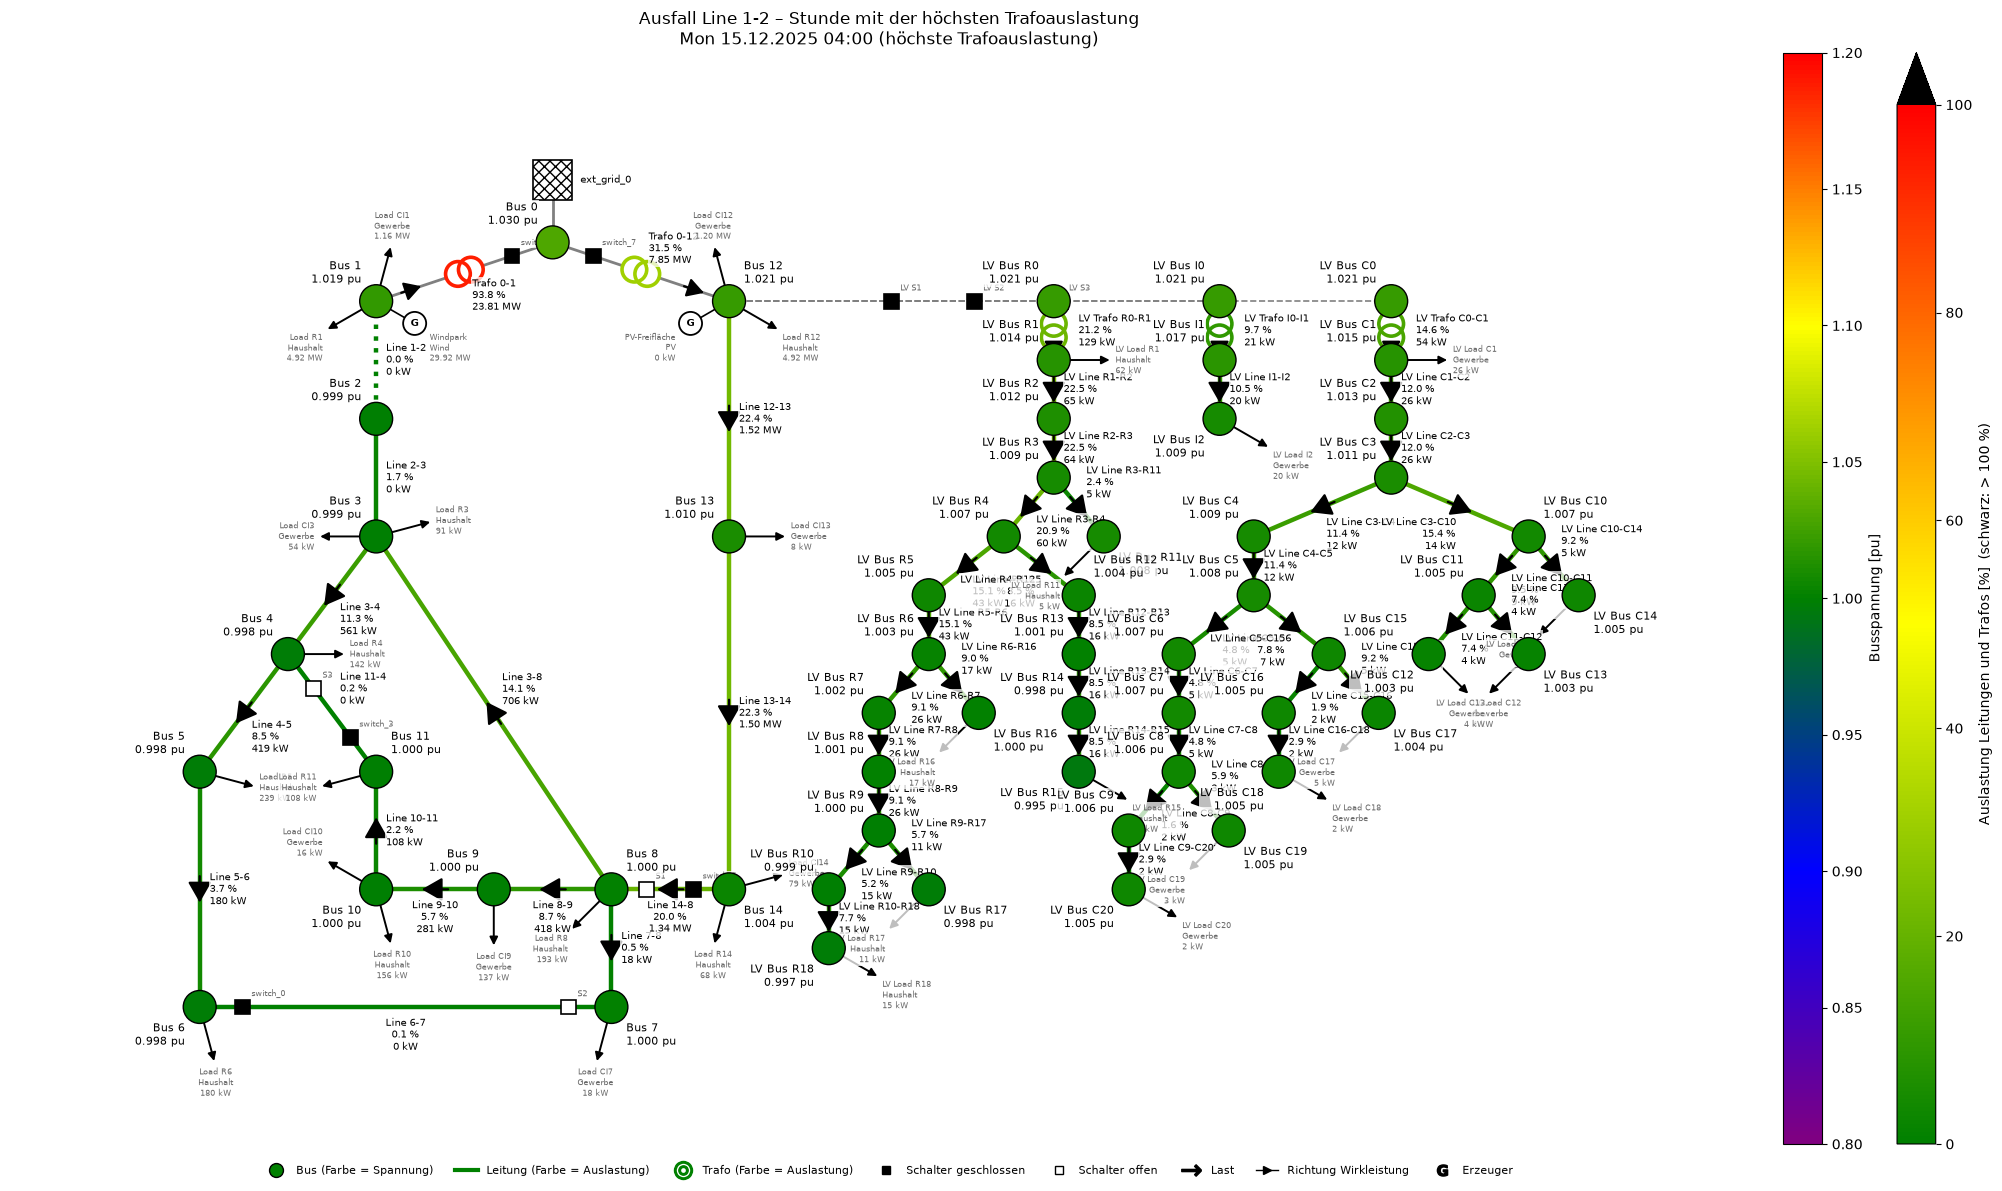

In [25]:
schlimmster = d_werte.drop(index="ohne Ausfall")["Trafo max HS/MS [%]"].astype(float).idxmax()
s = detail[schlimmster]
tl = s.results.trafo_loading[["Trafo 0-1", "Trafo 0-12"]]
p_ex = s.results.ext_grid_p_mw.squeeze()
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
x = np.arange(len(tl))
for c, farbe in zip(tl.columns, ("tab:blue", "tab:orange")):
    axes[0].plot(x, tl[c], color=farbe, lw=0.8, label=c)
axes[0].axhline(100, color="red", ls="--", lw=1)
axes[0].set_ylabel("Auslastung [%]")
axes[0].set_title(f"Ausfall {schlimmster} (höchste Trafoauslastung) – alle 12 Wochen")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[1].fill_between(x, p_ex, 0, where=p_ex < 0, color="tab:green", alpha=0.6, label="Rückspeisung")
axes[1].fill_between(x, p_ex, 0, where=p_ex >= 0, color="tab:gray", alpha=0.5, label="Bezug")
axes[1].set_ylabel("Austausch 110 kV [MW]")
monate = s.results.info["month"].to_numpy()
starts = [i for i in range(len(monate)) if i == 0 or monate[i] != monate[i - 1]]
axes[1].set_xticks(starts, [Month[m].label[:3] for m in monate[starts]])
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
s.createDiagram(Diagram.NETWORK, time=["max_trafo"], title=f"Ausfall {schlimmster} – Stunde mit der höchsten Trafoauslastung")

**Ergebnis Zeitreihen mit ausgefallener Leitung:**

- In **keiner** der sieben Zeitreihen wird eine Arbeitsgrenze verletzt; das Ortsnetz bleibt durch die rONT-Regelung immer im Planungsband. Die gewählte Kombination ist für Leitungsausfälle über das ganze Jahr (n-1)-sicher, nicht nur in den drei geprüften Stunden.
- **Ausfälle mit S1 (Line 1-2, 2-3):** Abgang 1 wird über den langen Weg aus Trafo 0-12 versorgt. Die MS-Spannung liegt in 202 bzw. 238 Stunden unter dem Planungsband (niedrigster Wert 0,932 pu), die Spannungsstützung schließt S2 und S3 zeitweise (66 bzw. 74 Schaltungen). Die Verluste steigen um rund 50 %. Die höchste Trafoauslastung (93,8 %) tritt bei **Rückspeisung** auf: Trafo 0-1 führt dann fast nur noch die Windleistung zurück ins 110-kV-Netz (Abbildung).
- **Ausfälle in Abgang 2 (Line 12-13, 13-14):** Bus 13 und 14 werden über S1 aus Abgang 1 versorgt; die höchste Leitungsauslastung steigt auf 86,9 %, die Spannung bleibt in höchstens 47 Stunden knapp unter 0,95 pu.
- **Ausfälle mit S2 oder S3:** Diese Ausfälle sind unkritisch (höchstens 105 Stunden unter dem Planungsband bei Line 3-8, gleiche Trafoauslastung wie ohne Ausfall).
- **Rückspeisung:** Die Zahl der Stunden mit Rückspeisung (262 bis 263) und die höchste Rückspeisung (16,1 MW) ändern sich durch die Ausfälle nicht, weil beide Anlagen direkt an den Sammelschienen einspeisen.

## 7 Ergebnis

- **Anschluss:** Windpark (30 MW) und PV-Freiflächenanlage (10 MWp) lassen sich im CIGRE-MV-Netz nur an den Sammelschienen der 110/20-kV-Transformatoren anschließen (Bus 1 oder Bus 12). In den Abgängen überlasten sie die Leitungen, die nur für etwa 5 MVA ausgelegt sind. In der Praxis werden Anlagen dieser Größe ebenfalls über ein eigenes Kabel direkt an die Sammelschiene des Umspannwerks angeschlossen.
- **Entscheidung:** Windpark an **Bus 1**, PV-Anlage an **Bus 12**. Die Entscheidung beruht jetzt auf zwei deutlichen Unterschieden statt auf Hundertsteln: Bei einem Trafoausfall gehen höchstens 30 statt 40 MW Erzeugung verloren (n-1), und Trafo 0-1 ist im Normalbetrieb um 3,8 Prozentpunkte weniger ausgelastet. Unterschiede unter den Relevanzschwellen (0,005 pu, 1 Prozentpunkt, 10 % der Stunden, 1 MW) gelten als gleichwertig.
- **(n-1):** Für Leitungsausfälle ist das Netz mit der gewählten Kombination über das ganze Jahr (n-1)-sicher; der Wiederversorgungsplan aus Teil 3b gilt unverändert. Der Ausfall eines 110/20-kV-Trafos ist nicht (n-1)-sicher. Bei Rückspeisung darf S1 nach einem Trafoausfall erst geschlossen werden, wenn die Erzeugung an der betroffenen Sammelschiene abgeschaltet ist.
- **Ortsnetz:** Die Profile für Haushalte mit PV und Speicher senken den Strombezug im Sommer deutlich, ändern aber die Winterspitze kaum.
- **Nächster Schritt:** Mit diesen Anschlussbussen werden die drei Szenarien einzeln und kombiniert für alle Schalterstellungen S1–S3 untersucht, einschließlich hoher und niedriger Einspeise- und Lastsituationen, Blindleistung und Lastflussumkehr.

### Quellen

[1] BDEW, „Hinweise zu den aktualisierten Standardlastprofilen Strom“, Anwendungshilfe, Berlin, 17.03.2025. Online: https://bdew.de/media/documents/2025-03-17_AWH_Aktualisierte_SLP_Strom_2025_Ver%C3%B6ffentlichung.pdf

[19] A. J. Schwab, *Elektroenergiesysteme: Erzeugung, Transport, Übertragung und Verteilung elektrischer Energie*, 3. Aufl. Berlin, Heidelberg: Springer, 2012, doi: 10.1007/978-3-642-21958-0. Verwendet: Kap. 1 ((n-1)-Prinzip, S. 6 f.), Kap. 11.3.1 (offene Ringnetze, Wiederversorgung, S. 521 f.).

[22] C. Kost et al., „Stromgestehungskosten Erneuerbare Energien“, Fraunhofer ISE, Freiburg, Juni 2021. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/DE2021_ISE_Studie_Stromgestehungskosten_Erneuerbare_Energien.pdf

[23] KfW Research, „Fast 13 Millionen Haushalte nutzen Energiewendetechnologien“, Pressemitteilung, 12.09.2024 (KfW-Energiewendebarometer). Online: https://www.kfw.de/%C3%9Cber-die-KfW/Newsroom/Aktuelles/Pressemitteilungen-Details_821696.html

[24] Fraunhofer ISE, „Photovoltaics Report“, Freiburg. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/Photovoltaics-Report.pdf

*Bei [22] und [24] Seiten bzw. Folien ergänzen und die Ausgabe von [24] prüfen.*